# Classificação de uso e cobertura do solo com EuroSAT

**Trabalho individual — Disciplina PAI**  
**Notebook principal — protocolo v1.5.0 — versão final executada em 12/10/2026**

> **Entrega básica concluída.** As 23 células de código foram executadas em ordem no Google Colab, em uma sessão reiniciada com GPU Tesla T4, sem saídas de erro. Os candidatos foram selecionados exclusivamente pela validação; o conjunto de teste foi acessado somente depois do congelamento do protocolo e não orientou ajustes posteriores. A recarga dos dois checkpoints e a reprodução das predições finais foram verificadas.


## 1. Problema, objetivo e pergunta experimental

Este trabalho desenvolve um classificador de imagens de satélite do EuroSAT. Para cada recorte RGB de entrada, o modelo atribui uma entre dez classes de uso ou cobertura do solo.

**Pergunta experimental:** no protocolo definido para este trabalho, como uma CNN simples treinada do zero e uma MobileNetV2 pré-treinada no ImageNet, com base congelada e cabeça classificadora treinável, se comparam em qualidade de classificação e custo de treinamento?

A comparação envolve arquiteturas e inicializações diferentes e, portanto, não isola causalmente apenas o efeito do pré-treinamento.

### Limites da entrega básica

A tarefa é a classificação de um recorte inteiro. Segmentação de pixels, detecção de objetos, monitoramento temporal, uso multiespectral e aplicação operacional no Brasil estão fora do escopo. Possíveis aplicações ambientais servem como motivação, não como capacidades comprovadas por este experimento.


## 2. Base de dados — descrição inicial

O EuroSAT foi construído a partir de imagens do satélite Sentinel-2. Este projeto utiliza a distribuição RGB obtida do registro Zenodo `10.5281/zenodo.7711810`. O arquivo foi validado com MD5 `f46e308c4d50d4bf32fedad2d3d62f3b`; a auditoria local confirmou 27.000 imagens JPEG legíveis, todas RGB e com dimensão 64 × 64.

As dez classes confirmadas são `AnnualCrop`, `Forest`, `HerbaceousVegetation`, `Highway`, `Industrial`, `Pasture`, `PermanentCrop`, `Residential`, `River` e `SeaLake`. As contagens auditadas e a divisão congelada são apresentadas na Seção 9.


## 3. Requisitos acadêmicos e escopo da entrega

### Itens obrigatórios contemplados

- descrição clara do problema e da base utilizada;
- explicação da metodologia;
- relato dos experimentos;
- análise dos resultados e conclusões;
- células de texto cobrindo esses elementos no próprio notebook.

### Escopo consolidado

- trabalho individual com o dataset EuroSAT RGB;
- execução no Google Colab;
- entrega principal em um notebook `.ipynb` executado e explicado;
- comparação central entre uma CNN simples e uma MobileNetV2 congelada;
- uso de fontes primárias, resultados medidos e artefatos verificáveis;
- ausência de augmentation e de fine-tuning na entrega básica.


## 4. Protocolo experimental

> Protocolo consolidado em 19/09/2026 e congelado antes do acesso ao conjunto de teste.

### Ferramentas e dados

- Python; TensorFlow/Keras para os modelos; scikit-learn para divisão e métricas; Matplotlib para gráficos;
- distribuição EuroSAT RGB;
- `F1 macro` como métrica principal, pois atribui o mesmo peso às classes; acurácia e métricas por classe como medidas complementares;
- divisão estratificada: 70% treino, 15% validação e 15% teste;
- semente mestre `42`, usada para rastreabilidade, sem promessa de reprodução bit a bit;
- uma configuração inicial e até duas revisões justificadas por abordagem.

### Seleção de checkpoint e candidato

1. O melhor checkpoint de uma tentativa é o de maior F1 macro no conjunto de validação.
2. Em empate no valor armazenado, prevalece a menor loss de validação; persistindo, a época mais antiga.
3. Entre tentativas da mesma abordagem, prevalece a maior F1 macro de validação; depois, menor loss de validação e menor custo de treinamento medido.
4. O teste não participou de checkpoint, seleção, ajuste ou inspeção de erros antes da avaliação final.

### Definição de tentativa e orçamento

Uma execução foi considerada tentativa formal quando completou uma avaliação de validação ou quando seus resultados parciais orientaram uma mudança experimental. Interrupções externas retomadas com o mesmo estado e configuração não criaram nova tentativa. Reexecuções motivadas por erro técnico foram registradas separadamente.

### Duplicatas e divisão

Antes da divisão, foram verificadas duplicatas por bytes e por pixels decodificados. A política definida manteria somente o primeiro caminho em ordem lexicográfica para duplicatas de pixels com o mesmo rótulo; conteúdo idêntico com rótulos conflitantes bloquearia a divisão. Nenhuma duplicata ou conflito foi encontrado.

### Augmentation, mudanças e custo

O experimento básico foi executado sem augmentation. O custo foi descrito por tempo de treinamento, épocas executadas e parâmetros totais/treináveis. Tempos foram tratados como comparação direta apenas quando as evidências de ambiente eram equivalentes; diferenças remanescentes foram explicitadas como limitações.


## 5. Integridade experimental

- a mesma divisão por imagem e a mesma ordem de classes foram reutilizadas pelos dois modelos;
- a auditoria de duplicatas ocorreu antes do congelamento da divisão;
- estatísticas e atualizações de pesos utilizaram somente treino e validação;
- o conjunto de teste permaneceu reservado até os dois candidatos finais serem congelados;
- testes técnicos das Etapas 2 e 4 não foram tratados como resultados científicos e seus pesos foram descartados;
- tentativas formais, correções técnicas, configurações, versões e checkpoints foram registrados;
- a semente fixa melhora a rastreabilidade, mas não garante reprodução bit a bit;
- sem grupos geográficos confiáveis, a divisão aleatória não demonstra generalização para regiões novas;
- uma única divisão e poucas tentativas não demonstram superioridade estatística;
- após a avaliação final, nenhuma decisão de modelagem foi alterada com base no teste.


## 6. Mapa dos cinco itens acadêmicos

| Item obrigatório | Conteúdo neste notebook | Etapas responsáveis |
|---|---|---|
| Descrição do problema | objetivo, motivação, entrada, saída e limites | 1 e 8 |
| Descrição da base | origem, classes, exemplos, qualidade e divisão | 2 e 3 |
| Metodologia | preparação, arquiteturas, treinamento e métricas | 4, 5 e 6 |
| Experimentos | configurações, tentativas, curvas e resultados reais | 5, 6 e 7 |
| Análise e conclusões | comparação, erros, limitações e resposta ao objetivo | 7 e 8 |


## 7. Registro de decisões e estado

| ID | Item | Estado |
|---|---|---|
| D01 | Trabalho individual, Colab e notebook principal | Confirmado |
| D02 | EuroSAT e comparação CNN × MobileNetV2 congelada | Confirmado |
| D03 | Ferramentas, RGB, F1 macro e divisão 70/15/15 | Aprovado em 19/09/2026 |
| D04 | Semente mestre 42 | Aprovado em 19/09/2026 |
| D05 | Máximo de 3 tentativas formais por abordagem | Aprovado em 19/09/2026 |
| D06 | Regras de seleção, desempate e definição de tentativa | Aprovado em 19/09/2026 |
| D07 | Política de duplicatas | Aprovado em 19/09/2026 |
| D08 | Sem augmentation na entrega básica | Aprovado em 19/09/2026 |
| D09 | Segunda tentativa formal da CNN em T4, sem mudança de hiperparâmetros | Concluída em 08/10/2026 |
| D10 | `cnn_attempt_2` selecionada pela maior F1 macro de validação | Congelado antes do teste |
| D11 | `mobilenetv2_initial_v1` selecionada pela validação | Congelado antes do teste |
| D12 | Avaliação final de 4.050 imagens, sem ajuste orientado pelo teste | Concluída em 12/10/2026 |
| D13 | Revisão final e organização da entrega | Concluída em 12/10/2026 |

**Estado final:** Etapas 1 a 8 concluídas. Os resultados da Etapa 7 permanecem como avaliação final da entrega básica.


## 8. Ambiente e aquisição dos dados

> **ETAPA 2 CONCLUÍDA.** Ambiente, GPU, persistência, download, integridade, amostras, treinamento técnico e recarga foram validados no Google Colab. Os caminhos exibidos são relativos à raiz configurável do projeto para preservar portabilidade e privacidade.

### Origem e condições de uso

A distribuição adotada é `EuroSAT_RGB.zip`, versão v2, publicada pelos autores no Zenodo. O registro informa 27.000 imagens, dez classes, JPEG com bandas R, G e B, tamanho de 94.658.721 bytes e checksum MD5 `f46e308c4d50d4bf32fedad2d3d62f3b`. O repositório dos autores declara licença MIT e recomenda observar os termos de dados Sentinel/Copernicus.

- Registro oficial: https://doi.org/10.5281/zenodo.7711810
- Repositório dos autores: https://github.com/phelber/EuroSAT
- Artigo: https://doi.org/10.1109/JSTARS.2019.2918242
- Consulta das fontes: 19/09/2026

O checksum calculado durante a execução foi comparado ao valor publicado no Zenodo. Isso verifica a integridade em relação ao arquivo oficial, não apenas a consistência de uma cópia local.


In [1]:
# Identificação do ambiente real do Google Colab — não instala nem altera pacotes.
import hashlib
import importlib.metadata as metadata
import json
import os
import platform
import shutil
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import tensorflow as tf
from PIL import Image

def package_version(name):
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

def total_ram_bytes():
    try:
        return os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES')
    except (AttributeError, ValueError):
        return None

gpu_devices = [device.name for device in tf.config.list_physical_devices('GPU')]
nvidia_smi = shutil.which('nvidia-smi')
gpu_detail = None
if nvidia_smi:
    result = subprocess.run(
        [nvidia_smi, '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
        capture_output=True, text=True, check=False
    )
    gpu_detail = result.stdout.strip() or result.stderr.strip()

disk = shutil.disk_usage('/content')
environment = {
    'collected_at_utc': datetime.now(timezone.utc).isoformat(),
    'python': sys.version.replace('\n', ' '),
    'platform': platform.platform(),
    'tensorflow': tf.__version__,
    'keras': package_version('keras'),
    'scikit_learn': package_version('scikit-learn'),
    'numpy': np.__version__,
    'matplotlib': package_version('matplotlib'),
    'pillow': package_version('pillow'),
    'gpu_devices': gpu_devices,
    'gpu_detail': gpu_detail,
    'ram_total_bytes': total_ram_bytes(),
    'content_disk_total_bytes': disk.total,
    'content_disk_free_bytes': disk.free,
}
print(json.dumps(environment, indent=2, ensure_ascii=False))


{
  "collected_at_utc": "2026-10-12T21:10:11.118781+00:00",
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "scikit_learn": "1.6.1",
  "numpy": "2.1.3",
  "matplotlib": "3.10.0",
  "pillow": "11.3.0",
  "gpu_devices": [
    "/physical_device:GPU:0"
  ],
  "gpu_detail": "Tesla T4, 15360 MiB, 580.82.07",
  "ram_total_bytes": 13605830656,
  "content_disk_total_bytes": 120942624768,
  "content_disk_free_bytes": 75467026432
}


### Persistência no Google Drive

O experimento usa uma única raiz configurável. `EUROSAT_PROJECT_DIR` aponta para o diretório persistente do projeto e, na ausência da variável, assume o caminho genérico `/content/drive/MyDrive/EuroSAT_Project`.

Nenhum ID de pasta, URL privada, credencial ou caminho pessoal é gravado no notebook. Dados, configurações, checkpoints, métricas e registros de auditoria são organizados sob a mesma raiz do projeto, com caminhos relativos portáveis para a futura publicação do repositório.

In [2]:
from google.colab import drive

drive.mount('/content/drive')
DRIVE_MOUNT = Path('/content/drive').resolve()
DEFAULT_PROJECT_DIR = '/content/drive/MyDrive/EuroSAT_Project'

PROJECT_DIR = Path(
    os.environ.get('EUROSAT_PROJECT_DIR', DEFAULT_PROJECT_DIR)
).expanduser().resolve()

if DRIVE_MOUNT != PROJECT_DIR and DRIVE_MOUNT not in PROJECT_DIR.parents:
    raise ValueError(
        'EUROSAT_PROJECT_DIR deve apontar para um diretório dentro do Drive montado.'
    )
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(
        'A pasta configurada por EUROSAT_PROJECT_DIR não foi encontrada. '
        'Crie a pasta ou defina a variável somente no ambiente de execução.'
    )

RAW_DIR = PROJECT_DIR / 'data' / 'raw'
TECH_DIR = PROJECT_DIR / 'artifacts' / 'technical_checks'
LOG_DIR = PROJECT_DIR / 'logs'
for directory in (RAW_DIR, TECH_DIR, LOG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

persistence_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
persistence_path = LOG_DIR / f'persistence_check_{persistence_id}.json'
payload = {'id': persistence_id, 'status': 'write_requested'}
with persistence_path.open('x', encoding='utf-8') as file:
    json.dump(payload, file, indent=2)
with persistence_path.open('r', encoding='utf-8') as file:
    restored = json.load(file)
assert restored == payload

print(json.dumps({
    'project_root_available': True,
    'persistence_check': str(persistence_path.relative_to(PROJECT_DIR)),
}, indent=2, ensure_ascii=False))

Mounted at /content/drive
{
  "project_root_available": true,
  "persistence_check": "logs/persistence_check_20261012T211038348205Z.json"
}


### Download rastreável e verificação do arquivo bruto

A célula abaixo reutiliza um ZIP existente somente quando seu MD5 coincide com o checksum oficial. Uma cópia divergente não é apagada nem sobrescrita automaticamente. O download é gravado primeiro em arquivo temporário e só é promovido ao nome final depois da validação.


In [3]:
import requests

ZENODO_RECORD = 'https://doi.org/10.5281/zenodo.7711810'
RGB_URL = 'https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1'
EXPECTED_MD5 = 'f46e308c4d50d4bf32fedad2d3d62f3b'
EXPECTED_SIZE_BYTES = 94658721
ZIP_PATH = RAW_DIR / 'EuroSAT_RGB.zip'

def file_md5(path, chunk_size=1024 * 1024):
    digest = hashlib.md5()
    with Path(path).open('rb') as file:
        for chunk in iter(lambda: file.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()

if ZIP_PATH.exists():
    existing_md5 = file_md5(ZIP_PATH)
    if existing_md5 != EXPECTED_MD5:
        raise RuntimeError(
            f'Arquivo existente preservado, mas inválido: {ZIP_PATH}; MD5={existing_md5}'
        )
    download_status = 'reused_verified_file'
else:
    temporary_path = RAW_DIR / 'EuroSAT_RGB.zip.part'
    if temporary_path.exists():
        raise RuntimeError(f'Arquivo temporário já existe e foi preservado: {temporary_path}')
    with requests.get(RGB_URL, stream=True, timeout=(30, 300)) as response:
        response.raise_for_status()
        with temporary_path.open('xb') as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)
    downloaded_md5 = file_md5(temporary_path)
    if downloaded_md5 != EXPECTED_MD5:
        raise RuntimeError(
            f'Download preservado para diagnóstico, mas MD5 divergiu: {downloaded_md5}'
        )
    os.replace(temporary_path, ZIP_PATH)
    download_status = 'downloaded_and_verified'

actual_size = ZIP_PATH.stat().st_size
actual_md5 = file_md5(ZIP_PATH)
assert actual_size == EXPECTED_SIZE_BYTES, (actual_size, EXPECTED_SIZE_BYTES)
assert actual_md5 == EXPECTED_MD5, (actual_md5, EXPECTED_MD5)
print(json.dumps({
    'status': download_status,
    'record': ZENODO_RECORD,
    'file': str(ZIP_PATH.relative_to(PROJECT_DIR)),
    'size_bytes': actual_size,
    'md5_calculated': actual_md5,
    'md5_matches_zenodo': True,
}, indent=2, ensure_ascii=False))


{
  "status": "reused_verified_file",
  "record": "https://doi.org/10.5281/zenodo.7711810",
  "file": "data/raw/EuroSAT_RGB.zip",
  "size_bytes": 94658721,
  "md5_calculated": "f46e308c4d50d4bf32fedad2d3d62f3b",
  "md5_matches_zenodo": true
}


### Extração temporária e leitura de uma pequena amostra

O ZIP bruto permanece preservado no Drive. Para evitar leitura lenta durante os experimentos, a extração desta etapa é feita no armazenamento temporário do Colab. Esta célula apenas confirma abertura, formato, modo de cor e classes encontradas; a auditoria integral pertence à Etapa 3.


In [4]:
import zipfile

EXTRACT_ROOT = Path('/content/eurosat_stage2')
EXPECTED_CLASSES = {
    'AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
    'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake',
}

def safe_extract(zip_path, destination):
    destination = destination.resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if destination != target and destination not in target.parents:
                raise RuntimeError(f'Caminho inseguro no ZIP: {member.filename}')
        archive.extractall(destination)

def find_dataset_dir(root):
    for current_path, directory_names, _ in os.walk(root):
        if EXPECTED_CLASSES.issubset(set(directory_names)):
            return Path(current_path)
    return None

EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)
DATASET_DIR = find_dataset_dir(EXTRACT_ROOT)
if DATASET_DIR is None:
    safe_extract(ZIP_PATH, EXTRACT_ROOT)
    DATASET_DIR = find_dataset_dir(EXTRACT_ROOT)
if DATASET_DIR is None:
    raise RuntimeError(
        f'Não foi localizada uma pasta contendo as dez classes do EuroSAT em {EXTRACT_ROOT}'
    )

class_dirs = sorted(path for path in DATASET_DIR.iterdir() if path.is_dir())
sample_records = []
for class_dir in class_dirs[:5]:
    sample_path = next(iter(sorted(class_dir.glob('*.jpg'))), None)
    if sample_path is None:
        continue
    with Image.open(sample_path) as image:
        image.load()
        sample_records.append({
            'class': class_dir.name,
            'relative_path': str(sample_path.relative_to(DATASET_DIR)),
            'format': image.format,
            'mode': image.mode,
            'size': list(image.size),
        })

if not sample_records:
    raise RuntimeError(f'Nenhuma amostra JPEG encontrada em {DATASET_DIR}')
if any(record['mode'] != 'RGB' for record in sample_records):
    raise RuntimeError(f'Amostra não RGB encontrada: {sample_records}')

print(json.dumps({
    'dataset_dir': str(DATASET_DIR),
    'classes_observed_in_directory': [path.name for path in class_dirs],
    'samples_checked': sample_records,
    'scope': 'small_stage2_sample_not_full_audit',
}, indent=2, ensure_ascii=False))


{
  "dataset_dir": "/content/eurosat_stage2/EuroSAT_RGB",
  "classes_observed_in_directory": [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
  ],
  "samples_checked": [
    {
      "class": "AnnualCrop",
      "relative_path": "AnnualCrop/AnnualCrop_1.jpg",
      "format": "JPEG",
      "mode": "RGB",
      "size": [
        64,
        64
      ]
    },
    {
      "class": "Forest",
      "relative_path": "Forest/Forest_1.jpg",
      "format": "JPEG",
      "mode": "RGB",
      "size": [
        64,
        64
      ]
    },
    {
      "class": "HerbaceousVegetation",
      "relative_path": "HerbaceousVegetation/HerbaceousVegetation_1.jpg",
      "format": "JPEG",
      "mode": "RGB",
      "size": [
        64,
        64
      ]
    },
    {
      "class": "Highway",
      "relative_path": "Highway/Highway_1.jpg",
      "format": "JPEG",
      "mode": "R

### Passo técnico de treinamento, salvamento e recarga

Este teste usa um lote sintético e uma rede descartável. Ele demonstra apenas que o ambiente consegue calcular uma atualização de pesos e persistir/recarregar um modelo. A loss não mede qualidade e os pesos gerados não serão usados nos experimentos formais.


In [5]:
tf.keras.utils.set_random_seed(42)
run_id = datetime.now(timezone.utc).strftime('stage2_tech_%Y%m%dT%H%M%S%fZ')
checkpoint_path = TECH_DIR / f'{run_id}.keras'
log_path = LOG_DIR / f'{run_id}.json'
if checkpoint_path.exists() or log_path.exists():
    raise FileExistsError('Identificador técnico já existe; nada foi sobrescrito.')

technical_model = tf.keras.Sequential([
    tf.keras.Input(shape=(64, 64, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),
    tf.keras.layers.Conv2D(4, 3, activation='relu'),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(10, activation='softmax'),
])
technical_model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
)
rng = np.random.default_rng(42)
synthetic_images = rng.integers(0, 256, size=(8, 64, 64, 3), dtype=np.uint8)
synthetic_labels = np.arange(8, dtype=np.int32) % 10
loss_value = float(technical_model.train_on_batch(synthetic_images, synthetic_labels))
predictions_before = technical_model.predict(synthetic_images[:2], verbose=0)
technical_model.save(checkpoint_path)
restored_model = tf.keras.models.load_model(checkpoint_path)
predictions_after = restored_model.predict(synthetic_images[:2], verbose=0)
max_prediction_difference = float(np.max(np.abs(predictions_before - predictions_after)))
np.testing.assert_allclose(predictions_before, predictions_after, rtol=1e-5, atol=1e-6)

technical_result = {
    'run_id': run_id,
    'purpose': 'technical_environment_check_only',
    'synthetic_batch_shape': list(synthetic_images.shape),
    'loss_after_one_update': loss_value,
    'checkpoint': str(checkpoint_path.relative_to(PROJECT_DIR)),
    'checkpoint_size_bytes': checkpoint_path.stat().st_size,
    'reload_max_prediction_difference': max_prediction_difference,
    'reload_tolerance_rtol': 1e-5,
    'reload_tolerance_atol': 1e-6,
    'reload_verified': True,
    'formal_experiment_weights': False,
    'environment': environment,
}
with log_path.open('x', encoding='utf-8') as file:
    json.dump(technical_result, file, indent=2, ensure_ascii=False)
with log_path.open('r', encoding='utf-8') as file:
    restored_log = json.load(file)
assert restored_log['run_id'] == run_id
print(json.dumps(technical_result, indent=2, ensure_ascii=False))
print(f'Log recarregado: {log_path.relative_to(PROJECT_DIR)}')


{
  "run_id": "stage2_tech_20261012T211045300619Z",
  "purpose": "technical_environment_check_only",
  "synthetic_batch_shape": [
    8,
    64,
    64,
    3
  ],
  "loss_after_one_update": 2.278226375579834,
  "checkpoint": "artifacts/technical_checks/stage2_tech_20261012T211045300619Z.keras",
  "checkpoint_size_bytes": 23479,
  "reload_max_prediction_difference": 0.0,
  "reload_tolerance_rtol": 1e-05,
  "reload_tolerance_atol": 1e-06,
  "reload_verified": true,
  "formal_experiment_weights": false,
  "environment": {
    "collected_at_utc": "2026-10-12T21:10:11.118781+00:00",
    "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
    "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
    "tensorflow": "2.21.0",
    "keras": "3.13.2",
    "scikit_learn": "1.6.1",
    "numpy": "2.1.3",
    "matplotlib": "3.10.0",
    "pillow": "11.3.0",
    "gpu_devices": [
      "/physical_device:GPU:0"
    ],
    "gpu_detail": "Tesla T4, 15360 MiB, 580.82.07",
    "ram_total_bytes": 13

### Registro de execução da Etapa 2

As células desta seção foram executadas em ordem no Google Colab. A execução confirmou o ambiente e o hardware registrados, a persistência da pasta do projeto, a integridade do ZIP RGB pelo tamanho e pelo MD5 oficiais, a leitura de amostras RGB e uma verificação técnica com loss finita. O checkpoint técnico foi salvo, recarregado e produziu predições equivalentes; o log persistente também foi relido com sucesso.

O arquivo válido foi reutilizado sem novo download. Esses artefatos constituem verificações técnicas de infraestrutura e não resultados comparativos dos modelos.


## 9. Auditoria e divisão

> **ETAPA 3 CONCLUÍDA.** A auditoria foi executada sobre o mesmo ZIP validado na Etapa 2. O ambiente de auditoria e as versões das bibliotecas foram registrados em `audit_summary.json`; os resultados abaixo derivam dos bytes efetivamente examinados, e não apenas das contagens publicadas.

### Procedimento

Para cada imagem foram registrados: identificador estável derivado do caminho relativo, classe, índice da classe, tamanho do arquivo, SHA-256 dos bytes, SHA-256 dos pixels decodificados, formato, dimensões, modo, número de canais e legibilidade. Igualdade de bytes e igualdade de pixels decodificados foram verificadas separadamente.

A política definida antes da divisão manteria somente o primeiro caminho em ordem lexicográfica para duplicatas de pixels com o mesmo rótulo. Qualquer grupo idêntico com rótulos conflitantes bloquearia a divisão. Nenhum desses casos ocorreu.

A divisão foi estratificada por classe em 70% treino, 15% validação e 15% teste. Dentro de cada classe, as imagens foram ordenadas pelo SHA-256 de `42|caminho_relativo`; essa regra determinística evita um novo sorteio em execuções futuras. A reconstrução independente produziu arquivos `inventory.csv` e `split.csv` idênticos aos originais.

### Resultado da qualidade

- 27.000 arquivos de imagem encontrados e 27.000 imagens legíveis;
- todas as imagens em JPEG, modo RGB e dimensão 64 × 64;
- nenhum arquivo inesperado ou ilegível;
- nenhuma duplicata por bytes e nenhuma duplicata por pixels decodificados;
- nenhuma exclusão e nenhum conflito de rótulo;
- todas as dez classes representadas em treino, validação e teste.

### Limitação geográfica

Os autores descrevem o EuroSAT como georreferenciado, mas esta distribuição RGB contém apenas diretórios por classe e arquivos JPEG cujos nomes expõem a classe e um número sequencial. Não foram encontrados, no arquivo utilizado, coordenadas nem identificadores documentados de cena/local que permitissem agrupar as imagens geograficamente. Portanto, esta divisão aleatória estratificada **não demonstra generalização para regiões não vistas**; ausência de duplicatas exatas também não prova independência espacial.


### Contagens congeladas

| Classe | Total | Treino | Validação | Teste |
|---|---:|---:|---:|---:|
| AnnualCrop | 3.000 | 2.100 | 450 | 450 |
| Forest | 3.000 | 2.100 | 450 | 450 |
| HerbaceousVegetation | 3.000 | 2.100 | 450 | 450 |
| Highway | 2.500 | 1.750 | 375 | 375 |
| Industrial | 2.500 | 1.750 | 375 | 375 |
| Pasture | 2.000 | 1.400 | 300 | 300 |
| PermanentCrop | 2.500 | 1.750 | 375 | 375 |
| Residential | 3.000 | 2.100 | 450 | 450 |
| River | 2.500 | 1.750 | 375 | 375 |
| SeaLake | 3.000 | 2.100 | 450 | 450 |
| **Total** | **27.000** | **18.900** | **4.050** | **4.050** |

As interseções de identificadores e hashes de pixels entre treino, validação e teste são vazias. O conjunto de teste permaneceu reservado até o congelamento dos candidatos na Etapa 7.


In [6]:
# Recarrega os artefatos congelados, verifica seus hashes e reproduz a atribuição.
import csv
import importlib.util

STAGE3_DIR = PROJECT_DIR / 'artifacts' / 'stage3_audit'
STAGE3_MODULE_PATH = PROJECT_DIR / 'src' / 'stage3_audit.py'
STAGE3_SUMMARY_PATH = STAGE3_DIR / 'audit_summary.json'

if not STAGE3_SUMMARY_PATH.exists():
    subprocess.run([
        sys.executable, str(STAGE3_MODULE_PATH),
        '--zip', str(ZIP_PATH),
        '--extract-root', str(EXTRACT_ROOT),
        '--output-dir', str(STAGE3_DIR),
    ], check=True)

with STAGE3_SUMMARY_PATH.open(encoding='utf-8') as file:
    stage3_summary = json.load(file)

for file_name, expected_sha256 in stage3_summary['control_file_sha256'].items():
    calculated_sha256 = hashlib.sha256((STAGE3_DIR / file_name).read_bytes()).hexdigest()
    assert calculated_sha256 == expected_sha256, file_name

spec = importlib.util.spec_from_file_location('stage3_audit', STAGE3_MODULE_PATH)
stage3_audit = importlib.util.module_from_spec(spec)
spec.loader.exec_module(stage3_audit)

with (STAGE3_DIR / 'inventory.csv').open(encoding='utf-8', newline='') as file:
    inventory_rows = list(csv.DictReader(file))
for row in inventory_rows:
    row['eligible'] = row['eligible'].lower() == 'true'
    row['readable'] = row['readable'].lower() == 'true'
with (STAGE3_DIR / 'split.csv').open(encoding='utf-8', newline='') as file:
    persisted_split = list(csv.DictReader(file))
reproduced_split = stage3_audit.make_split(inventory_rows)
assert reproduced_split == persisted_split
assert stage3_summary['split']['verification']['reproduced_identically']
print(json.dumps({
    'eligible_images': stage3_summary['inventory']['eligible_images'],
    'excluded_images': stage3_summary['inventory']['excluded_images'],
    'split_counts': stage3_summary['split']['counts'],
    'intersections': stage3_summary['split']['verification']['intersections'],
    'reproduced_identically': reproduced_split == persisted_split,
}, indent=2, ensure_ascii=False))


{
  "eligible_images": 27000,
  "excluded_images": 0,
  "split_counts": {
    "test": 4050,
    "train": 18900,
    "validation": 4050
  },
  "intersections": {
    "train__validation": {
      "image_ids": 0,
      "pixel_hashes": 0
    },
    "train__test": {
      "image_ids": 0,
      "pixel_hashes": 0
    },
    "validation__test": {
      "image_ids": 0,
      "pixel_hashes": 0
    }
  },
  "reproduced_identically": true
}


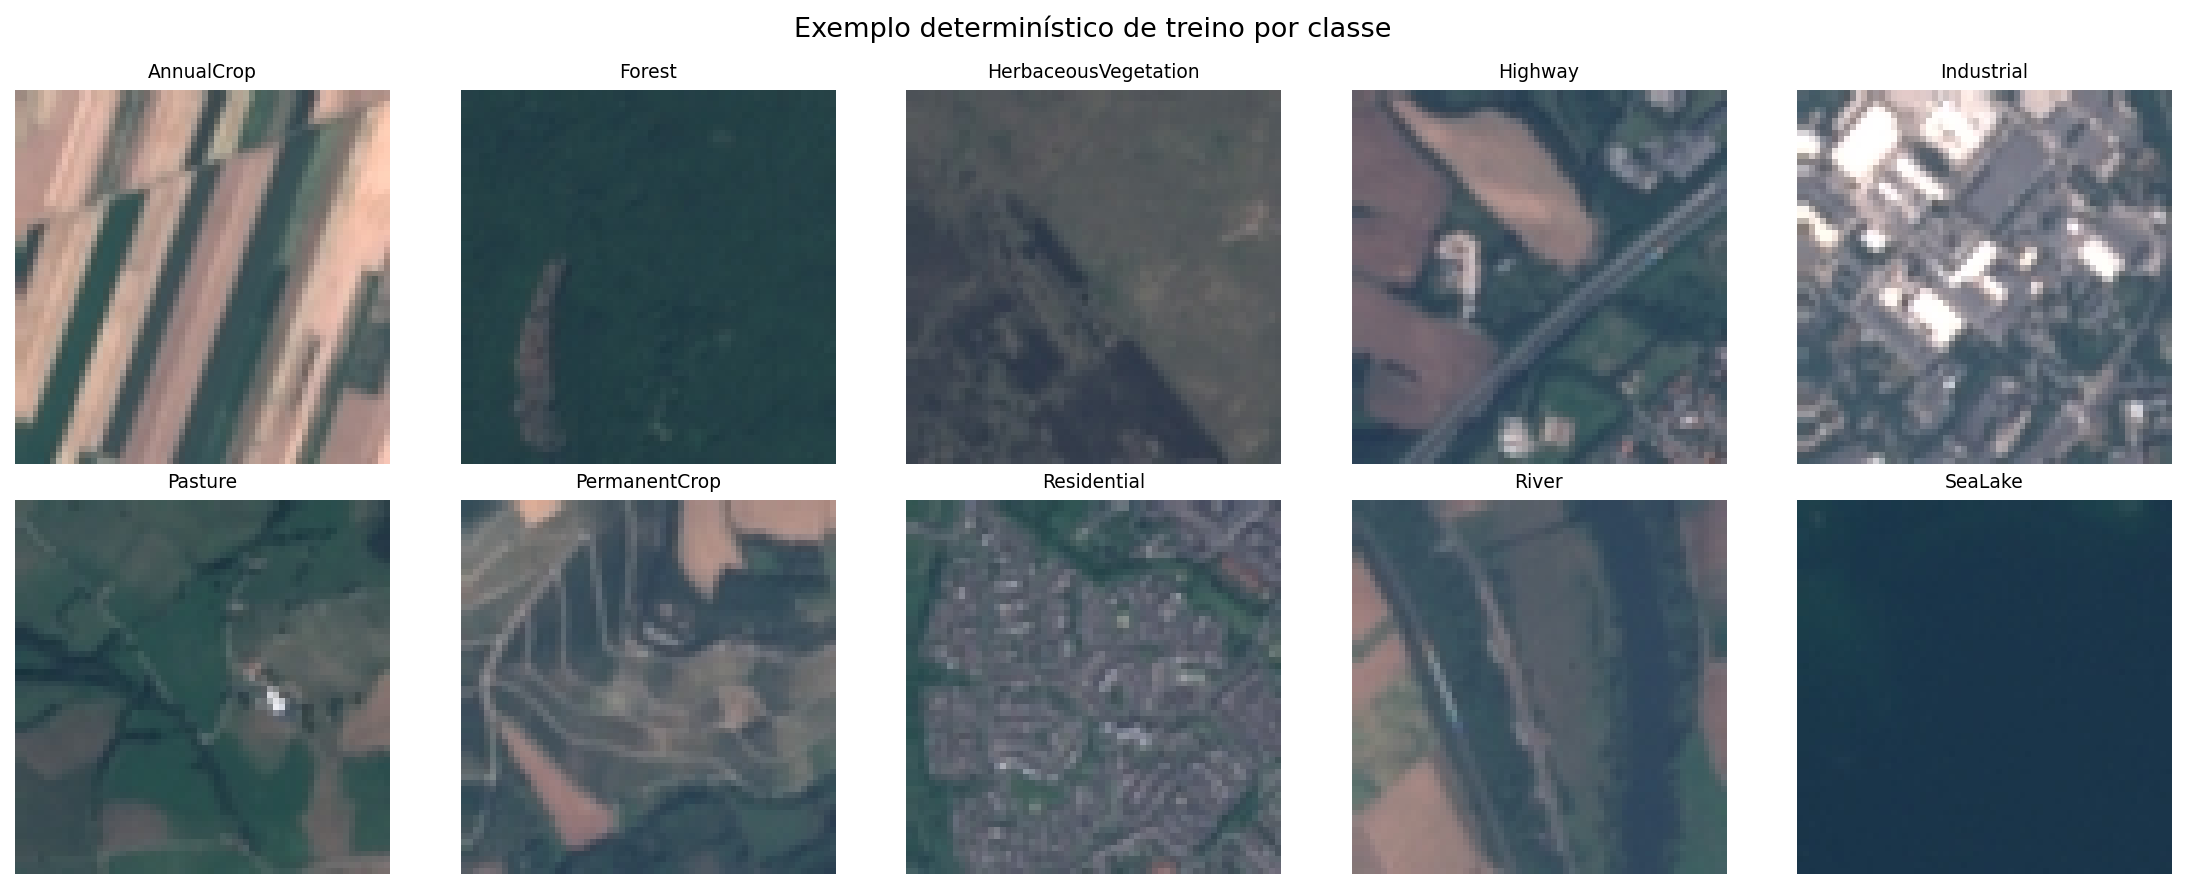

In [7]:
# Exemplos selecionados deterministicamente somente do conjunto de treino.
from IPython.display import display
display(Image.open(STAGE3_DIR / 'train_examples.png'))


### Artefatos persistidos

A pasta `artifacts/stage3_audit/` contém `inventory.csv`, `split.csv`, `split_config.json`, `classes.json`, `exclusions.csv`, `duplicate_groups.csv`, `audit_summary.json`, `train_examples.json` e `train_examples.png`. O módulo reproduzível está em `src/stage3_audit.py`. Os arquivos brutos não foram modificados.


## 10. Metodologia e pipeline

> **ETAPA 4 CONCLUÍDA.** Os dois fluxos foram validados tecnicamente no Google Colab. A execução comprovou loss finita, atualização dos pesos treináveis, congelamento da base MobileNetV2 e equivalência das predições após recarga. Nenhuma imagem do teste foi utilizada.

### Configuração inicial aprovada

As imagens permanecem na resolução nativa de 64 × 64. Isso evita interpolar detalhes que não existem no dado original e permite aplicar o mesmo tamanho de entrada às duas abordagens. O lote inicial é 64 imagens. A CNN recebe pixels reescalados para [0, 1]; a MobileNetV2 recebe pixels reescalados para [-1, 1], que é o formato esperado pelo pré-processamento oficial da arquitetura. As duas abordagens usam Adam, taxa inicial de aprendizado 0,001, no máximo 20 épocas e parada antecipada por F1 macro de validação com paciência de cinco épocas.

A CNN é uma arquitetura pequena treinada do zero. A MobileNetV2 usa pesos ImageNet com a base totalmente congelada e uma cabeça treinável. A resolução nativa de 64 × 64 e os demais valores foram confirmados para os experimentos formais. A MobileNetV2 utiliza os pesos ImageNet disponibilizados para 224 × 224 de forma convolucional sobre a entrada 64 × 64; essa diferença fica registrada e não implica criação de detalhes por interpolação.

O teste usa somente dois lotes de treino e dois lotes de validação por modelo. A métrica F1 macro usada no fluxo formal é calculada sobre todo o conjunto de validação fornecido ao callback, nunca como média de F1 por lote. No teste técnico, o callback recebe apenas a pequena amostra de validação explicitamente separada para essa finalidade. O conjunto de teste não é materializado, decodificado ou usado nesta etapa.

### Resultado do teste técnico

A CNN e a MobileNetV2 concluíram dois lotes de treino e dois de validação. Os tempos medidos no ajuste técnico foram aproximadamente 12,28 s e 22,19 s, respectivamente. As métricas desses poucos lotes não são resultados científicos e não orientaram ajustes. Os checkpoints técnicos permanecem separados e não serão carregados nos treinamentos formais.


In [8]:
import csv
import gc
import hashlib
import json
import os
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import tensorflow as tf
from sklearn.metrics import f1_score

required_stage_variables = ('PROJECT_DIR', 'DATASET_DIR', 'STAGE3_DIR', 'stage3_summary')
missing_stage_variables = [
    name for name in required_stage_variables if name not in globals()
]
if missing_stage_variables:
    raise RuntimeError(
        'Execute as seções 8 e 9 em ordem antes da seção 10. '
        f'Variáveis ausentes: {", ".join(missing_stage_variables)}'
    )

tf.keras.utils.set_random_seed(42)

MASTER_SEED = 42
IMAGE_SIZE = (64, 64)
NUM_CLASSES = 10
CLASS_NAMES = [
    'AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
    'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake',
]
CLASS_TO_INDEX = {class_name: index for index, class_name in enumerate(CLASS_NAMES)}

STAGE4_DIR = PROJECT_DIR / 'artifacts' / 'stage4_pipeline'
STAGE4_TECHNICAL_DIR = STAGE4_DIR / 'technical_probes'
for directory in (STAGE4_DIR, STAGE4_TECHNICAL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SPLIT_PATH = STAGE3_DIR / 'split.csv'
CLASSES_PATH = STAGE3_DIR / 'classes.json'
if not SPLIT_PATH.exists() or not CLASSES_PATH.exists():
    raise FileNotFoundError('Artefatos congelados da Etapa 3 não foram encontrados.')

expected_split_sha256 = stage3_summary['control_file_sha256']['split.csv']
actual_split_sha256 = hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest()
if actual_split_sha256 != expected_split_sha256:
    raise RuntimeError('O hash de split.csv diverge do resumo congelado da Etapa 3.')

with CLASSES_PATH.open(encoding='utf-8') as file:
    persisted_class_to_index = json.load(file)
if persisted_class_to_index != CLASS_TO_INDEX:
    raise RuntimeError('A ordem de classes persistida não corresponde ao protocolo aprovado.')

with SPLIT_PATH.open(encoding='utf-8', newline='') as file:
    split_rows = list(csv.DictReader(file))
if not split_rows:
    raise RuntimeError('split.csv está vazio.')

split_counts = Counter(row['split'] for row in split_rows)
expected_counts = stage3_summary['split']['counts']
if dict(split_counts) != expected_counts:
    raise RuntimeError(f'Contagens de split.csv divergentes: {dict(split_counts)} != {expected_counts}')
if set(split_counts) != {'train', 'validation', 'test'}:
    raise RuntimeError(f'Conjuntos inesperados em split.csv: {sorted(split_counts)}')

def records_for(split_name):
    records = []
    for row in split_rows:
        if row['split'] != split_name:
            continue
        class_name = row['class_name']
        class_index = int(row['class_index'])
        if CLASS_TO_INDEX.get(class_name) != class_index:
            raise RuntimeError(f'Rótulo inconsistente em {row["relative_path"]}')
        image_path = DATASET_DIR / row['relative_path']
        if not image_path.is_file():
            raise FileNotFoundError(f'Imagem da divisão congelada não encontrada: {row["relative_path"]}')
        records.append((str(image_path), class_index, row['relative_path']))
    if not records:
        raise RuntimeError(f'Não há registros para {split_name}.')
    return records

train_records = records_for('train')
validation_records = records_for('validation')

MODEL_SPECS = {
    'cnn': {
        'family': 'simple_cnn_from_scratch',
        'image_size': list(IMAGE_SIZE),
        'batch_size': 64,
        'optimizer': 'Adam',
        'learning_rate': 1e-3,
        'loss': 'sparse_categorical_crossentropy',
        'max_epochs': 20,
        'early_stopping_patience': 5,
        'checkpoint_monitor': 'val_f1_macro',
        'checkpoint_mode': 'max',
        'preprocessing': 'Rescaling pixels from [0, 255] to [0, 1]',
    },
    'mobilenetv2': {
        'family': 'MobileNetV2_ImageNet_frozen_base',
        'image_size': list(IMAGE_SIZE),
        'batch_size': 64,
        'optimizer': 'Adam',
        'learning_rate': 1e-3,
        'loss': 'sparse_categorical_crossentropy',
        'max_epochs': 20,
        'early_stopping_patience': 5,
        'checkpoint_monitor': 'val_f1_macro',
        'checkpoint_mode': 'max',
        'preprocessing': 'Rescaling pixels from [0, 255] to [-1, 1] for MobileNetV2',
    },
}

PIPELINE_CONFIG = {
    'version': 1,
    'status': 'technical_check_pending_confirmation_for_formal_training',
    'master_seed': MASTER_SEED,
    'class_names': CLASS_NAMES,
    'input_range_before_model_preprocessing': [0, 255],
    'split': {
        'file': 'artifacts/stage3_audit/split.csv',
        'sha256': actual_split_sha256,
        'counts': dict(split_counts),
        'test_reserved': True,
    },
    'technical_probe': {
        'train_batches': 2,
        'validation_batches': 2,
        'epochs': 1,
        'formal_experiment_weights': False,
    },
    'models': MODEL_SPECS,
}
CONFIG_PATH = STAGE4_DIR / 'pipeline_config_v1.json'
if CONFIG_PATH.exists():
    with CONFIG_PATH.open(encoding='utf-8') as file:
        persisted_config = json.load(file)
    if persisted_config != PIPELINE_CONFIG:
        raise RuntimeError('A configuração persistida diverge da configuração atual; nada foi sobrescrito.')
else:
    with CONFIG_PATH.open('x', encoding='utf-8') as file:
        json.dump(PIPELINE_CONFIG, file, indent=2, ensure_ascii=False)

print(json.dumps({
    'split_sha256_verified': True,
    'split_counts': dict(split_counts),
    'train_records_loaded': len(train_records),
    'validation_records_loaded': len(validation_records),
    'test_records_materialized': False,
    'config': str(CONFIG_PATH.relative_to(PROJECT_DIR)),
    'config_status': PIPELINE_CONFIG['status'],
}, indent=2, ensure_ascii=False))


{
  "split_sha256_verified": true,
  "split_counts": {
    "test": 4050,
    "train": 18900,
    "validation": 4050
  },
  "train_records_loaded": 18900,
  "validation_records_loaded": 4050,
  "test_records_materialized": false,
  "config": "artifacts/stage4_pipeline/pipeline_config_v1.json",
  "config_status": "technical_check_pending_confirmation_for_formal_training"
}


In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def gpu_memory_snapshot():
    """Return GPU memory information when the active runtime exposes it."""
    try:
        info = tf.config.experimental.get_memory_info('GPU:0')
        return {key: int(value) for key, value in info.items()}
    except (RuntimeError, ValueError, tf.errors.InvalidArgumentError):
        return None



def make_dataset(records, batch_size, training):
    paths = [record[0] for record in records]
    labels = [record[1] for record in records]
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(records),
            seed=MASTER_SEED,
            reshuffle_each_iteration=True,
        )

    def decode_and_resize(path, label):
        image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        image = tf.image.resize(image, IMAGE_SIZE, antialias=True)
        image = tf.cast(image, tf.float32)
        image = tf.ensure_shape(image, (*IMAGE_SIZE, 3))
        return image, tf.cast(label, tf.int32)

    return dataset.map(decode_and_resize, num_parallel_calls=AUTOTUNE).batch(
        batch_size, drop_remainder=False
    ).prefetch(AUTOTUNE)


def build_cnn(spec):
    regularizer = tf.keras.regularizers.l2(1e-4)
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='image')
    x = tf.keras.layers.Rescaling(1.0 / 255.0, name='cnn_rescale_0_1')(inputs)
    for filters in (32, 64, 128):
        x = tf.keras.layers.Conv2D(
            filters, 3, padding='same', activation='relu',
            kernel_regularizer=regularizer,
        )(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.25, seed=MASTER_SEED)(x)
    x = tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=regularizer)(x)
    x = tf.keras.layers.Dropout(0.20, seed=MASTER_SEED + 1)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='class_probabilities')(x)
    model = tf.keras.Model(inputs, outputs, name='eurosat_simple_cnn')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=spec['learning_rate']),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )
    return model


def build_mobilenetv2(spec, weights='imagenet', compile_model=True):
    base = tf.keras.applications.MobileNetV2(
        input_shape=(*IMAGE_SIZE, 3),
        include_top=False,
        weights=weights,
        name='mobilenetv2_base',
    )
    base.trainable = False
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3), name='image')
    x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name='mobilenetv2_rescale_minus1_1')(inputs)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.20, seed=MASTER_SEED)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='class_probabilities')(x)
    model = tf.keras.Model(inputs, outputs, name='eurosat_mobilenetv2_frozen')
    if compile_model:
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=spec['learning_rate']),
            loss=tf.keras.losses.SparseCategoricalCrossentropy(),
            metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
        )
    return model


def load_model_for_inference(model_name, spec, checkpoint_path):
    """Restore a checkpoint without trusting nested-model trainable flags."""
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Checkpoint não encontrado: {checkpoint_path.name}')
    if model_name == 'cnn':
        return tf.keras.models.load_model(checkpoint_path, compile=False)
    if model_name != 'mobilenetv2':
        raise ValueError(f'Modelo desconhecido: {model_name}')

    # A mesma arquitetura formal é construída já congelada. O arquivo .keras
    # fornece somente os pesos; não importamos seus flags de treinabilidade.
    model = build_mobilenetv2(spec, weights=None, compile_model=False)
    model.load_weights(checkpoint_path, skip_mismatch=False)
    assert_model_contract(model, 'mobilenetv2')
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=spec['learning_rate']),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )
    return model


def assert_model_contract(model, model_name):
    batch_images, batch_labels = next(iter(make_dataset(validation_records, 2, training=False).take(1)))
    predictions = model(batch_images, training=False).numpy()
    if predictions.shape != (2, NUM_CLASSES):
        raise RuntimeError(f'Saída inesperada de {model_name}: {predictions.shape}')
    np.testing.assert_allclose(predictions.sum(axis=1), np.ones(2), rtol=1e-5, atol=1e-6)
    if not np.isfinite(predictions).all():
        raise RuntimeError(f'Predições não finitas em {model_name}.')
    if not np.issubdtype(batch_labels.numpy().dtype, np.integer):
        raise RuntimeError('Os rótulos não são inteiros.')
    if model_name == 'mobilenetv2':
        base = model.get_layer('mobilenetv2_base')
        if base.trainable or any(layer.trainable for layer in base.layers):
            raise RuntimeError('A base da MobileNetV2 deveria estar inteiramente congelada.')


def parameter_counts(model):
    total = int(sum(np.prod(variable.shape) for variable in model.weights))
    trainable = int(sum(np.prod(variable.shape) for variable in model.trainable_weights))
    return {'total': total, 'trainable': trainable, 'non_trainable': total - trainable}


MODEL_BUILDERS = {'cnn': build_cnn, 'mobilenetv2': build_mobilenetv2}
print('Construtores, carregadores e contratos do pipeline preparados.')


Construtores, carregadores e contratos do pipeline preparados.


In [10]:
def macro_f1_on_dataset(model, dataset):
    labels = []
    predictions = []
    for images, batch_labels in dataset:
        probabilities = model(images, training=False).numpy()
        labels.append(batch_labels.numpy())
        predictions.append(np.argmax(probabilities, axis=1))
    if not labels:
        raise RuntimeError('O conjunto de validação fornecido ao callback está vazio.')
    y_true = np.concatenate(labels)
    y_pred = np.concatenate(predictions)
    return float(f1_score(y_true, y_pred, average='macro', zero_division=0))


def is_better_candidate(candidate, current_best, tolerance=1e-12):
    if current_best is None:
        return True
    if candidate['f1_macro'] > current_best['f1_macro'] + tolerance:
        return True
    if abs(candidate['f1_macro'] - current_best['f1_macro']) <= tolerance:
        if candidate['val_loss'] < current_best['val_loss'] - tolerance:
            return True
    return False


class ValidationF1Checkpoint(tf.keras.callbacks.Callback):
    def __init__(self, validation_dataset, checkpoint_path, metric_name='val_f1_macro'):
        super().__init__()
        self.validation_dataset = validation_dataset
        self.checkpoint_path = Path(checkpoint_path)
        self.metric_name = metric_name
        self.best = None
        self.records = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        f1_macro = macro_f1_on_dataset(self.model, self.validation_dataset)
        val_loss = float(logs.get('val_loss', np.nan))
        if not np.isfinite(val_loss):
            raise RuntimeError('val_loss ausente ou não finita; checkpoint não será selecionado.')
        candidate = {
            'epoch': int(epoch) + 1,
            'f1_macro': f1_macro,
            'val_loss': val_loss,
        }
        selected = is_better_candidate(candidate, self.best)
        candidate['selected'] = selected
        logs[self.metric_name] = f1_macro
        self.records.append(candidate)
        if selected:
            self.checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
            temporary_path = self.checkpoint_path.with_name(
                f'{self.checkpoint_path.stem}.tmp.keras'
            )
            if temporary_path.exists():
                raise FileExistsError(f'Checkpoint temporário existente: {temporary_path.name}')
            self.model.save(temporary_path, overwrite=False)
            os.replace(temporary_path, self.checkpoint_path)
            self.best = candidate


def make_formal_callbacks(validation_dataset, checkpoint_path, patience):
    selector = ValidationF1Checkpoint(validation_dataset, checkpoint_path)
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_f1_macro', mode='max', patience=patience,
        restore_best_weights=False,
    )
    return [selector, early_stopping], selector


# Verifica explicitamente a regra aprovada: F1 macro, depois menor loss, depois época mais antiga.
baseline = {'epoch': 1, 'f1_macro': 0.50, 'val_loss': 0.80}
assert is_better_candidate({'epoch': 2, 'f1_macro': 0.51, 'val_loss': 0.90}, baseline)
assert is_better_candidate({'epoch': 2, 'f1_macro': 0.50, 'val_loss': 0.70}, baseline)
assert not is_better_candidate({'epoch': 2, 'f1_macro': 0.50, 'val_loss': 0.80}, baseline)
assert not is_better_candidate({'epoch': 2, 'f1_macro': 0.49, 'val_loss': 0.10}, baseline)
print('Cálculo de F1 macro e regra de checkpoint validados para uso formal posterior.')


Cálculo de F1 macro e regra de checkpoint validados para uso formal posterior.


In [11]:
TECHNICAL_TRAIN_BATCHES = PIPELINE_CONFIG['technical_probe']['train_batches']
TECHNICAL_VALIDATION_BATCHES = PIPELINE_CONFIG['technical_probe']['validation_batches']

def json_float_history(history):
    return {
        key: [float(value) for value in values]
        for key, values in history.history.items()
    }


def run_technical_probe(model_name):
    spec = MODEL_SPECS[model_name]
    run_id = datetime.now(timezone.utc).strftime(f'stage4_{model_name}_%Y%m%dT%H%M%S%fZ')
    run_dir = STAGE4_TECHNICAL_DIR / run_id
    run_dir.mkdir(parents=False, exist_ok=False)
    checkpoint_path = run_dir / 'technical_selected.keras'
    result_path = run_dir / 'technical_result.json'

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(MASTER_SEED)
    memory_before = gpu_memory_snapshot()

    loading_started = time.perf_counter()
    train_dataset = make_dataset(train_records, spec['batch_size'], training=True)
    validation_dataset = make_dataset(validation_records, spec['batch_size'], training=False)
    train_probe = train_dataset.take(TECHNICAL_TRAIN_BATCHES)
    validation_probe = validation_dataset.take(TECHNICAL_VALIDATION_BATCHES)
    probe_images, probe_labels = next(iter(validation_probe.take(1)))
    data_loading_seconds = time.perf_counter() - loading_started
    if probe_images.shape[1:] != (*IMAGE_SIZE, 3):
        raise RuntimeError(f'Forma de entrada inesperada: {probe_images.shape}')
    if float(tf.reduce_min(probe_images)) < 0 or float(tf.reduce_max(probe_images)) > 255:
        raise RuntimeError('Faixa inesperada antes do preprocessing específico do modelo.')

    initialization_started = time.perf_counter()
    model = MODEL_BUILDERS[model_name](spec)
    initialization_seconds = time.perf_counter() - initialization_started
    assert_model_contract(model, model_name)
    parameters = parameter_counts(model)
    memory_after_initialization = gpu_memory_snapshot()

    weights_before = [variable.numpy().copy() for variable in model.trainable_weights]
    selector = ValidationF1Checkpoint(validation_probe, checkpoint_path, 'technical_probe_f1_macro')
    training_started = time.perf_counter()
    history = model.fit(
        train_probe,
        validation_data=validation_probe,
        epochs=PIPELINE_CONFIG['technical_probe']['epochs'],
        callbacks=[selector],
        verbose=2,
    )
    training_seconds = time.perf_counter() - training_started
    memory_after_training = gpu_memory_snapshot()

    weights_after = [variable.numpy() for variable in model.trainable_weights]
    weights_changed = any(
        not np.array_equal(before, after)
        for before, after in zip(weights_before, weights_after)
    )
    if not weights_changed:
        raise RuntimeError('Nenhum peso treinável mudou no teste técnico.')
    if not checkpoint_path.is_file() or selector.best is None:
        raise RuntimeError('O checkpoint técnico não foi criado.')
    if not all(np.isfinite(value) for value in history.history['loss']):
        raise RuntimeError('Loss não finita no teste técnico.')
    if not all(np.isfinite(value) for value in history.history['val_loss']):
        raise RuntimeError('Loss de validação não finita no teste técnico.')

    predictions_before = model.predict(probe_images, verbose=0)
    reload_started = time.perf_counter()
    reloaded_model = load_model_for_inference(model_name, spec, checkpoint_path)
    predictions_after = reloaded_model.predict(probe_images, verbose=0)
    reload_seconds = time.perf_counter() - reload_started
    max_prediction_difference = float(np.max(np.abs(predictions_before - predictions_after)))
    np.testing.assert_allclose(predictions_before, predictions_after, rtol=1e-5, atol=1e-6)

    result = {
        'run_id': run_id,
        'purpose': 'stage4_technical_pipeline_probe_only',
        'model': model_name,
        'formal_experiment_weights': False,
        'test_set_used': False,
        'train_batches': TECHNICAL_TRAIN_BATCHES,
        'validation_batches': TECHNICAL_VALIDATION_BATCHES,
        'batch_size': spec['batch_size'],
        'parameters': parameters,
        'base_frozen': model_name != 'mobilenetv2' or not model.get_layer('mobilenetv2_base').trainable,
        'loss_finite': True,
        'trainable_weights_changed': weights_changed,
        'checkpoint': str(checkpoint_path.relative_to(PROJECT_DIR)),
        'checkpoint_size_bytes': checkpoint_path.stat().st_size,
        'selection_records': selector.records,
        'history': json_float_history(history),
        'reload_max_prediction_difference': max_prediction_difference,
        'reload_tolerance_rtol': 1e-5,
        'reload_tolerance_atol': 1e-6,
        'reload_verified': True,
        'durations_seconds': {
            'data_loading': data_loading_seconds,
            'initialization': initialization_seconds,
            'technical_fit': training_seconds,
            'reload': reload_seconds,
        },
        'gpu_memory_bytes': {
            'before': memory_before,
            'after_initialization': memory_after_initialization,
            'after_technical_fit': memory_after_training,
        },
    }
    with result_path.open('x', encoding='utf-8') as file:
        json.dump(result, file, indent=2, ensure_ascii=False)
    return result


technical_results = [run_technical_probe(model_name) for model_name in ('cnn', 'mobilenetv2')]
summary_path = STAGE4_DIR / 'latest_technical_probe.json'
technical_summary = {
    'purpose': 'stage4_technical_pipeline_probe_only',
    'test_set_used': False,
    'split_sha256': actual_split_sha256,
    'results': technical_results,
}
with summary_path.open('w', encoding='utf-8') as file:
    json.dump(technical_summary, file, indent=2, ensure_ascii=False)

print(json.dumps({
    'status': 'technical_probe_completed',
    'test_set_used': False,
    'summary': str(summary_path.relative_to(PROJECT_DIR)),
    'models': [{
        'model': result['model'],
        'loss_finite': result['loss_finite'],
        'weights_changed': result['trainable_weights_changed'],
        'base_frozen': result['base_frozen'],
        'reload_verified': result['reload_verified'],
        'technical_fit_seconds': result['durations_seconds']['technical_fit'],
    } for result in technical_results],
}, indent=2, ensure_ascii=False))


2/2 - 11s - 6s/step - accuracy: 0.1016 - loss: 2.3263 - val_accuracy: 0.0000e+00 - val_loss: 2.2661 - technical_probe_f1_macro: 0.0000e+00


/tmp/ipykernel_2776/975360848.py:61: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
2/2 - 15s - 8s/step - accuracy: 0.1172 - loss: 3.2151 - val_accuracy: 0.2891 - val_loss: 1.8588 - technical_probe_f1_macro: 0.0448


{
  "status": "technical_probe_completed",
  "test_set_used": false,
  "summary": "artifacts/stage4_pipeline/latest_technical_probe.json",
  "models": [
    {
      "model": "cnn",
      "loss_finite": true,
      "weights_changed": true,
      "base_frozen": true,
      "reload_verified": true,
      "technical_fit_seconds": 11.294687382000006
    },
    {
      "model": "mobilenetv2",
      "loss_finite": true,
      "weights_changed": true,
      "base_frozen": true,
      "reload_verified": true,
      "technical_fit_seconds": 15.478069201999915
    }
  ]
}


### Registro de execução da Etapa 4

As quatro células desta seção foram executadas em ordem. A verificação confirmou o hash da divisão, o carregamento de treino e validação sem materializar o teste, a consistência de formas e rótulos, loss finita e alteração dos pesos treináveis nas duas abordagens. Na MobileNetV2, a base permaneceu congelada. Os checkpoints técnicos foram recarregados com predições equivalentes, e as medidas disponíveis de tempo e memória foram registradas.

O arquivo `artifacts/stage4_pipeline/latest_technical_probe.json` consolida essas evidências. Os pesos gerados nesta verificação foram classificados como técnicos, descartados para fins experimentais e não foram utilizados nos treinamentos formais das Etapas 5 e 6.


## 11. Experimento 1 — CNN simples

> **ETAPA 5 CONCLUÍDA.** Duas tentativas formais foram preservadas. A tentativa `cnn_attempt_2` foi selecionada pela regra aprovada antes de qualquer acesso ao conjunto de teste.

### Configuração mantida nas duas tentativas

- imagens RGB de 64 × 64, sem augmentation;
- lote de 64 imagens;
- mesma CNN pequena inicializada do zero com semente 42;
- Adam com taxa de aprendizado 0,001;
- entropia cruzada categórica esparsa;
- limite de 20 épocas;
- parada antecipada após cinco épocas sem melhora da F1 macro de validação;
- checkpoint selecionado por maior F1 macro, depois menor loss e, persistindo o empate, época mais antiga.

### Tentativas e seleção

| Tentativa | Melhor época | Loss de validação | Acurácia | F1 macro | Tempo registrado |
|---|---:|---:|---:|---:|---:|
| `cnn_attempt_1` | 20 | 0,5774 | 0,8141 | 0,8034 | 2.532,88 s |
| `cnn_attempt_2` | 19 | **0,5508** | **0,8220** | **0,8134** | 327,81 s |

`cnn_attempt_2` foi selecionada porque obteve a maior F1 macro de validação; portanto, o tempo não participou do desempate. Essa tentativa registrou explicitamente Tesla T4, TensorFlow 2.21.0, uso positivo de memória da GPU, recarga do checkpoint e ausência de uso do teste.

O tempo da primeira tentativa não é usado em comparação direta porque seu registro não identifica de forma auditável o modelo exato do acelerador. Essa limitação não afeta a seleção, que foi decidida pela métrica principal. Os registros originais permanecem preservados e o candidato selecionado foi consolidado em uma estrutura neutra no projeto principal, sem alteração de pesos, métricas, hiperparâmetros ou divisão dos dados.

In [12]:
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt

required_stage5_variables = (
    'PROJECT_DIR', 'STAGE4_DIR', 'MODEL_SPECS', 'MASTER_SEED', 'IMAGE_SIZE',
    'NUM_CLASSES', 'CLASS_NAMES', 'actual_split_sha256',
    'train_records', 'validation_records', 'make_dataset',
    'load_model_for_inference', 'assert_model_contract',
)
missing_stage5_variables = [
    name for name in required_stage5_variables if name not in globals()
]
if missing_stage5_variables:
    raise RuntimeError(
        'Execute as seções 8, 9 e 10 em ordem antes da seção 11. '
        f'Variáveis ausentes: {", ".join(missing_stage5_variables)}'
    )

STAGE4_SUMMARY_PATH = STAGE4_DIR / 'latest_technical_probe.json'
if not STAGE4_SUMMARY_PATH.is_file():
    raise FileNotFoundError('Resumo técnico da Etapa 4 não encontrado.')
with STAGE4_SUMMARY_PATH.open(encoding='utf-8') as file:
    stage4_technical_summary = json.load(file)
if stage4_technical_summary.get('test_set_used') is not False:
    raise RuntimeError('O resumo da Etapa 4 não confirma o isolamento do teste.')
stage4_models = {
    result['model']: result for result in stage4_technical_summary['results']
}
for required_model in ('cnn', 'mobilenetv2'):
    result = stage4_models.get(required_model)
    if not result:
        raise RuntimeError(f'Resultado técnico ausente: {required_model}')
    for flag in ('loss_finite', 'trainable_weights_changed', 'reload_verified'):
        if result.get(flag) is not True:
            raise RuntimeError(f'Validação técnica pendente: {required_model}.{flag}')
if stage4_models['mobilenetv2'].get('base_frozen') is not True:
    raise RuntimeError('A base congelada da MobileNetV2 não foi validada.')

CNN_SELECTION_DIR = PROJECT_DIR / 'artifacts' / 'stage5_cnn_selection'
CNN_ATTEMPT_ID = 'cnn_attempt_2'
CNN_ATTEMPT_DIR = CNN_SELECTION_DIR / 'attempts' / CNN_ATTEMPT_ID
CNN_CANDIDATE_PATH = CNN_SELECTION_DIR / 'selected_candidate.json'
CNN_COMPARISON_PATH = CNN_SELECTION_DIR / 'cnn_attempt_comparison.json'
CNN_SELECTION_REGISTRY_PATH = (
    CNN_SELECTION_DIR / 'selected_candidate_registry.json'
)
CNN_INTEGRITY_MANIFEST_PATH = CNN_SELECTION_DIR / 'integrity_manifest.json'
CNN_RUN_CONFIG_PATH = CNN_ATTEMPT_DIR / 'run_config.json'
CNN_RUN_STATE_PATH = CNN_ATTEMPT_DIR / 'run_state.json'

required_cnn_artifacts = (
    CNN_CANDIDATE_PATH,
    CNN_COMPARISON_PATH,
    CNN_SELECTION_REGISTRY_PATH,
    CNN_INTEGRITY_MANIFEST_PATH,
    CNN_RUN_CONFIG_PATH,
    CNN_RUN_STATE_PATH,
)
missing_cnn_artifacts = [
    str(path.relative_to(PROJECT_DIR))
    for path in required_cnn_artifacts
    if not path.is_file()
]
if missing_cnn_artifacts:
    raise FileNotFoundError(
        'Artefatos consolidados da CNN ausentes: '
        + ', '.join(missing_cnn_artifacts)
    )

CNN_SPEC = MODEL_SPECS['cnn']
formal_cnn_validation_dataset = make_dataset(
    validation_records, CNN_SPEC['batch_size'], training=False
)

print(json.dumps({
    'status': 'stage5_candidate_package_ready',
    'attempt_id': CNN_ATTEMPT_ID,
    'artifact_directory': str(CNN_SELECTION_DIR.relative_to(PROJECT_DIR)),
    'validation_examples': len(validation_records),
    'test_set_materialized': False,
}, indent=2, ensure_ascii=False))

{
  "status": "stage5_candidate_package_ready",
  "attempt_id": "cnn_attempt_2",
  "artifact_directory": "artifacts/stage5_cnn_selection",
  "validation_examples": 4050,
  "test_set_materialized": false
}


In [13]:
def write_json_atomically(path, payload):
    path = Path(path)
    temporary_path = path.with_name(f'{path.name}.tmp')
    with temporary_path.open('w', encoding='utf-8') as file:
        json.dump(payload, file, indent=2, ensure_ascii=False)
    os.replace(temporary_path, path)


def selected_record(records):
    selected = [record for record in records if record.get('selected')]
    return selected[-1] if selected else None


class PersistentValidationF1Checkpoint(tf.keras.callbacks.Callback):
    def __init__(self, validation_dataset, checkpoint_dir, records_path):
        super().__init__()
        self.validation_dataset = validation_dataset
        self.checkpoint_dir = Path(checkpoint_dir)
        self.records_path = Path(records_path)
        if self.records_path.exists():
            with self.records_path.open(encoding='utf-8') as file:
                self.records = json.load(file)
        else:
            self.records = []
        self.best = selected_record(self.records)

    def _next_checkpoint_path(self, epoch_number):
        base = self.checkpoint_dir / f'epoch_{epoch_number:03d}.keras'
        if not base.exists():
            return base
        retry = 1
        while True:
            candidate = self.checkpoint_dir / f'epoch_{epoch_number:03d}_retry_{retry}.keras'
            if not candidate.exists():
                return candidate
            retry += 1

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        epoch_number = int(epoch) + 1
        self.records = [
            record for record in self.records
            if int(record['epoch']) < epoch_number
        ]
        self.best = selected_record(self.records)
        f1_macro = macro_f1_on_dataset(self.model, self.validation_dataset)
        val_loss = float(logs.get('val_loss', np.nan))
        if not np.isfinite(val_loss):
            raise RuntimeError('val_loss ausente ou não finita; checkpoint não selecionado.')
        candidate = {
            'epoch': epoch_number,
            'f1_macro': f1_macro,
            'val_loss': val_loss,
        }
        candidate['selected'] = is_better_candidate(candidate, self.best)
        logs['val_f1_macro'] = f1_macro
        if candidate['selected']:
            checkpoint_path = self._next_checkpoint_path(epoch_number)
            self.model.save(checkpoint_path, overwrite=False)
            candidate['checkpoint'] = str(checkpoint_path.relative_to(PROJECT_DIR))
            self.best = candidate
        self.records.append(candidate)
        write_json_atomically(self.records_path, self.records)


class PersistentEpochTiming(tf.keras.callbacks.Callback):
    def __init__(self, timings_path):
        super().__init__()
        self.timings_path = Path(timings_path)
        if self.timings_path.exists():
            with self.timings_path.open(encoding='utf-8') as file:
                self.records = json.load(file)
        else:
            self.records = []
        self.started_at = None

    def on_epoch_begin(self, epoch, logs=None):
        self.started_at = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        epoch_number = int(epoch) + 1
        seconds = float(time.perf_counter() - self.started_at)
        self.records = [
            record for record in self.records
            if int(record['epoch']) < epoch_number
        ]
        self.records.append({'epoch': epoch_number, 'seconds': seconds})
        write_json_atomically(self.timings_path, self.records)


print('Callbacks persistentes de seleção, retomada e medição preparados.')


Callbacks persistentes de seleção, retomada e medição preparados.


In [14]:
with CNN_CANDIDATE_PATH.open(encoding='utf-8') as file:
    cnn_candidate = json.load(file)
with CNN_COMPARISON_PATH.open(encoding='utf-8') as file:
    cnn_attempt_comparison = json.load(file)
with CNN_SELECTION_REGISTRY_PATH.open(encoding='utf-8') as file:
    cnn_selection_registry = json.load(file)
with CNN_INTEGRITY_MANIFEST_PATH.open(encoding='utf-8') as file:
    cnn_integrity_manifest = json.load(file)
with CNN_RUN_CONFIG_PATH.open(encoding='utf-8') as file:
    cnn_run_config = json.load(file)
with CNN_RUN_STATE_PATH.open(encoding='utf-8') as file:
    cnn_run_state = json.load(file)

if cnn_candidate.get('attempt_id') != CNN_ATTEMPT_ID:
    raise RuntimeError('O candidato consolidado da CNN tem identificador inesperado.')
if cnn_candidate.get('attempt_number') != 2:
    raise RuntimeError('O candidato consolidado não corresponde à segunda tentativa.')
if cnn_candidate.get('model') != 'simple_cnn_from_scratch':
    raise RuntimeError('A arquitetura registrada para a CNN é inesperada.')
if cnn_candidate.get('status') != 'selected_after_validation':
    raise RuntimeError('O candidato CNN não está registrado como selecionado.')
if cnn_candidate.get('reload_verified') is not True:
    raise RuntimeError('A recarga do checkpoint CNN não foi confirmada.')
if cnn_candidate.get('original_checkpoint_loaded') is not False:
    raise RuntimeError('A segunda tentativa não confirma inicialização independente.')
if cnn_candidate.get('technical_checkpoint_loaded') is not False:
    raise RuntimeError('Um checkpoint técnico foi carregado indevidamente.')

if cnn_run_config.get('attempt_id') != CNN_ATTEMPT_ID:
    raise RuntimeError('A configuração da CNN pertence a outra tentativa.')
if cnn_run_config.get('status') != 'approved_formal_attempt':
    raise RuntimeError('A configuração da CNN não está aprovada.')
expected_cnn_configuration = {
    'seed': MASTER_SEED,
    'image_size': list(IMAGE_SIZE),
    'batch_size': CNN_SPEC['batch_size'],
    'optimizer': CNN_SPEC['optimizer'],
    'learning_rate': CNN_SPEC['learning_rate'],
    'loss': CNN_SPEC['loss'],
    'max_epochs': CNN_SPEC['max_epochs'],
    'early_stopping_patience': CNN_SPEC['early_stopping_patience'],
    'augmentation': False,
    'split_sha256': actual_split_sha256,
    'train_examples': len(train_records),
    'validation_examples': len(validation_records),
}
for key, expected_value in expected_cnn_configuration.items():
    if cnn_run_config.get(key) != expected_value:
        raise RuntimeError(f'Configuração divergente da CNN: {key}')

if cnn_run_state.get('status') != 'training_completed':
    raise RuntimeError('O estado persistido da CNN não está concluído.')
if cnn_run_state.get('attempt_id') != CNN_ATTEMPT_ID:
    raise RuntimeError('O estado persistido pertence a outra tentativa.')
if cnn_run_state.get('selected_checkpoint') != cnn_candidate.get(
    'selected_checkpoint'
):
    raise RuntimeError('O checkpoint diverge entre o estado e o candidato CNN.')

if cnn_selection_registry.get('selected_attempt_id') != CNN_ATTEMPT_ID:
    raise RuntimeError('O registro de seleção aponta para outra tentativa CNN.')
if cnn_selection_registry.get('selected_artifact_root') != 'EUROSAT_PROJECT_DIR':
    raise RuntimeError('A raiz lógica registrada para a CNN é inesperada.')
if cnn_attempt_comparison.get('recommended_attempt_id') != CNN_ATTEMPT_ID:
    raise RuntimeError('A comparação de validação recomenda outra tentativa CNN.')

records_by_attempt = {
    row['attempt_id']: row for row in cnn_attempt_comparison.get('attempts', [])
}
selected_comparison_record = records_by_attempt.get(CNN_ATTEMPT_ID)
if selected_comparison_record is None:
    raise RuntimeError('A segunda tentativa está ausente da comparação da CNN.')
for candidate_key, comparison_key in (
    ('loss', 'validation_loss'),
    ('accuracy', 'validation_accuracy'),
    ('f1_macro', 'validation_f1_macro'),
):
    if not np.isclose(
        float(cnn_candidate['validation_metrics'][candidate_key]),
        float(selected_comparison_record[comparison_key]),
        rtol=0.0,
        atol=1e-12,
    ):
        raise RuntimeError(f'Métrica divergente da CNN: {candidate_key}')

integrity_flags = (
    'weights_modified',
    'metrics_modified',
    'hyperparameters_modified',
    'data_split_modified',
)
for flag in integrity_flags:
    if cnn_integrity_manifest.get(flag) is not False:
        raise RuntimeError(f'O manifesto de integridade não confirma {flag}=false.')

for artifact_name, artifact_path in (
    ('candidate', CNN_CANDIDATE_PATH),
    ('comparison', CNN_COMPARISON_PATH),
    ('run_state', CNN_RUN_STATE_PATH),
    ('run_config', CNN_RUN_CONFIG_PATH),
    ('selection_registry', CNN_SELECTION_REGISTRY_PATH),
):
    calculated_sha256 = hashlib.sha256(artifact_path.read_bytes()).hexdigest()
    expected_sha256 = cnn_integrity_manifest['normalized_record_sha256'][
        artifact_name
    ]
    if calculated_sha256 != expected_sha256:
        raise RuntimeError(f'Hash divergente no artefato CNN: {artifact_name}')

cnn_checkpoint_path = PROJECT_DIR / cnn_candidate['selected_checkpoint']
if not cnn_checkpoint_path.is_file():
    raise FileNotFoundError('O checkpoint selecionado da CNN não foi encontrado.')
cnn_checkpoint_sha256 = hashlib.sha256(
    cnn_checkpoint_path.read_bytes()
).hexdigest()
expected_checkpoint_hashes = {
    cnn_candidate['selected_checkpoint_sha256'],
    cnn_selection_registry['selected_checkpoint_sha256'],
    cnn_integrity_manifest['checkpoint_sha256'],
}
if expected_checkpoint_hashes != {cnn_checkpoint_sha256}:
    raise RuntimeError('O hash do checkpoint da CNN diverge dos registros.')

cnn_runtime = cnn_candidate.get('runtime', {})
cnn_gpu_names = [
    str(detail.get('device_name', ''))
    for detail in cnn_runtime.get('gpu_details', [])
    if isinstance(detail, dict)
]
if (
    cnn_runtime.get('t4_confirmed') is not True
    or not any('T4' in name.upper() for name in cnn_gpu_names)
):
    raise RuntimeError('A execução em GPU T4 não foi confirmada para a CNN.')
if cnn_candidate.get('gpu_memory_evidence_verified') is not True:
    raise RuntimeError('A evidência de uso de memória da GPU não foi confirmada.')

for payload_name, payload in (
    ('candidate', cnn_candidate),
    ('comparison', cnn_attempt_comparison),
    ('selection_registry', cnn_selection_registry),
    ('integrity_manifest', cnn_integrity_manifest),
    ('run_config', cnn_run_config),
    ('run_state', cnn_run_state),
):
    if payload.get('test_set_used') is not False:
        raise RuntimeError(f'O artefato {payload_name} não preserva o teste.')

stage5_candidate = cnn_candidate
stage5_run_state = cnn_run_state
selected_candidate = cnn_candidate
CNN_SELECTED_CHECKPOINT_PATH = cnn_checkpoint_path

print(json.dumps({
    'status': 'stage5_candidate_integrity_verified',
    'attempts_considered': [row['attempt_id'] for row in cnn_attempt_comparison['attempts']],
    'selected_attempt_id': CNN_ATTEMPT_ID,
    'selection_basis': cnn_selection_registry['selection_basis'],
    'checkpoint_sha256_verified': True,
    'weights_modified_during_normalization': False,
    'metrics_modified_during_normalization': False,
    'test_set_used': False,
}, indent=2, ensure_ascii=False))

{
  "status": "stage5_candidate_integrity_verified",
  "attempts_considered": [
    "cnn_attempt_1",
    "cnn_attempt_2"
  ],
  "selected_attempt_id": "cnn_attempt_2",
  "selection_basis": "higher_validation_macro_f1",
  "checkpoint_sha256_verified": true,
  "weights_modified_during_normalization": false,
  "metrics_modified_during_normalization": false,
  "test_set_used": false
}


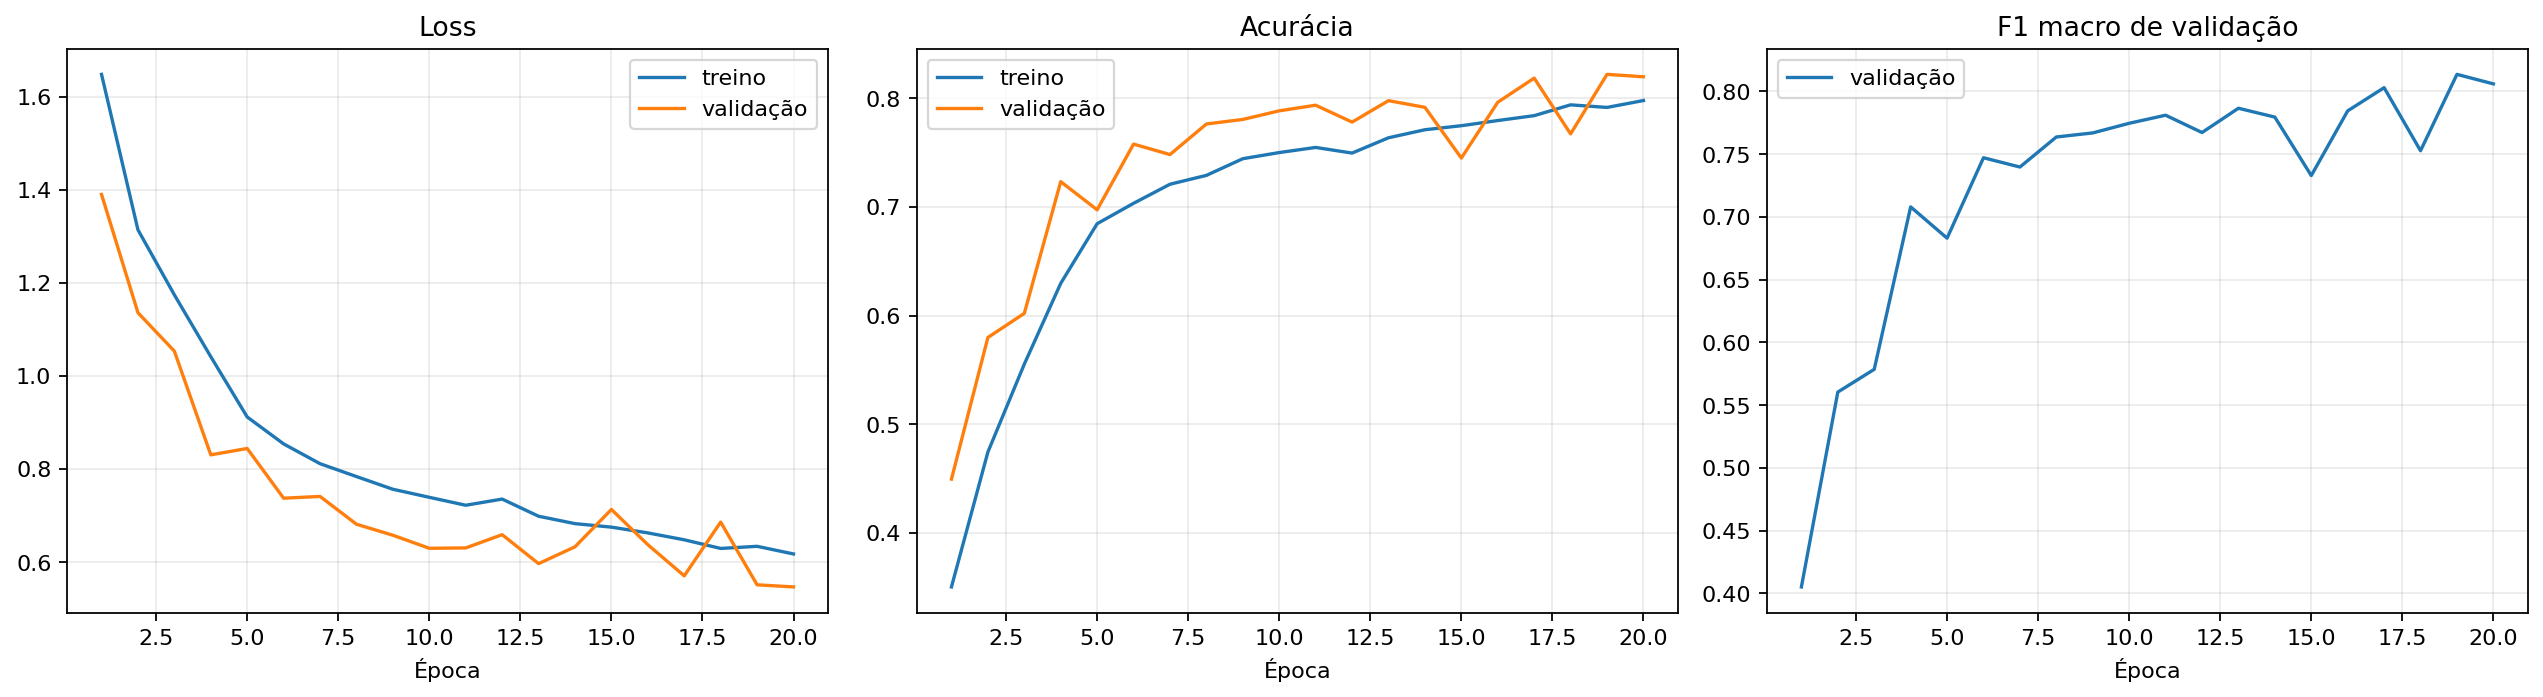

{
  "status": "stage5_cnn_candidate_verified",
  "attempt_id": "cnn_attempt_2",
  "epochs_completed": 20,
  "best_epoch": 19,
  "stop_reason": "maximum_epochs",
  "training_seconds": 327.80967778600007,
  "validation": {
    "loss": 0.5507717728614807,
    "accuracy": 0.8219753086419753,
    "f1_macro": 0.8133914043821164
  },
  "accelerator": [
    "Tesla T4"
  ],
  "selected_checkpoint": "artifacts/stage5_cnn_selection/attempts/cnn_attempt_2/selected_checkpoints/epoch_019.keras",
  "reload_verified": true,
  "test_set_used": false
}


In [15]:
CNN_VALIDATION_PREDICTIONS_PATH = (
    PROJECT_DIR / cnn_candidate['validation_predictions']
)
CNN_LEARNING_CURVES_PATH = PROJECT_DIR / cnn_candidate['learning_curves']
for required_path in (
    CNN_VALIDATION_PREDICTIONS_PATH,
    CNN_LEARNING_CURVES_PATH,
):
    if not required_path.is_file():
        raise FileNotFoundError(
            f'Artefato de validação da CNN ausente: {required_path.name}'
        )

with CNN_VALIDATION_PREDICTIONS_PATH.open(
    encoding='utf-8', newline=''
) as file:
    persisted_validation_rows = list(csv.DictReader(file))
if len(persisted_validation_rows) != len(validation_records):
    raise RuntimeError('Quantidade de predições persistidas da CNN divergente.')

tf.keras.backend.clear_session()
gc.collect()
selected_cnn_model = load_model_for_inference(
    'cnn', CNN_SPEC, CNN_SELECTED_CHECKPOINT_PATH
)
assert_model_contract(selected_cnn_model, 'cnn')

validation_probability_batches = []
validation_label_batches = []
for images, labels in formal_cnn_validation_dataset:
    validation_probability_batches.append(
        selected_cnn_model(images, training=False).numpy()
    )
    validation_label_batches.append(labels.numpy())
validation_probabilities = np.concatenate(validation_probability_batches)
validation_labels = np.concatenate(validation_label_batches)
validation_predictions = np.argmax(validation_probabilities, axis=1)

for record, label, prediction, persisted_row in zip(
    validation_records,
    validation_labels,
    validation_predictions,
    persisted_validation_rows,
):
    if persisted_row['relative_path'] != record[2]:
        raise RuntimeError('A ordem das predições de validação da CNN diverge.')
    if int(label) != int(record[1]):
        raise RuntimeError('O rótulo de validação da CNN está desalinhado.')
    if int(persisted_row['true_class_index']) != int(label):
        raise RuntimeError('O rótulo persistido da CNN está desalinhado.')
    if int(persisted_row['predicted_class_index']) != int(prediction):
        raise RuntimeError('A recarga da CNN produziu predição divergente.')

reloaded_validation_accuracy = float(accuracy_score(
    validation_labels, validation_predictions
))
reloaded_validation_f1_macro = float(f1_score(
    validation_labels,
    validation_predictions,
    labels=list(range(NUM_CLASSES)),
    average='macro',
    zero_division=0,
))
if not np.isclose(
    reloaded_validation_accuracy,
    cnn_candidate['validation_metrics']['accuracy'],
    rtol=0.0,
    atol=1e-7,
):
    raise RuntimeError('A acurácia da CNN não foi reproduzida após a recarga.')
if not np.isclose(
    reloaded_validation_f1_macro,
    cnn_candidate['validation_metrics']['f1_macro'],
    rtol=0.0,
    atol=1e-12,
):
    raise RuntimeError('A F1 macro da CNN não foi reproduzida após a recarga.')

display(Image.open(CNN_LEARNING_CURVES_PATH))
del selected_cnn_model
tf.keras.backend.clear_session()
gc.collect()

print(json.dumps({
    'status': 'stage5_cnn_candidate_verified',
    'attempt_id': cnn_candidate['attempt_id'],
    'epochs_completed': cnn_candidate['epochs_completed'],
    'best_epoch': cnn_candidate['best_epoch'],
    'stop_reason': cnn_candidate['stop_reason'],
    'training_seconds': cnn_candidate['training_seconds'],
    'validation': {
        'loss': cnn_candidate['validation_metrics']['loss'],
        'accuracy': reloaded_validation_accuracy,
        'f1_macro': reloaded_validation_f1_macro,
    },
    'accelerator': cnn_gpu_names,
    'selected_checkpoint': cnn_candidate['selected_checkpoint'],
    'reload_verified': True,
    'test_set_used': False,
}, indent=2, ensure_ascii=False))

### Registro da seleção da CNN

A execução registrada confirmou `cnn_attempt_2` como candidata final da CNN. Foram concluídas 20 épocas, com melhor checkpoint na época 19, F1 macro de validação de 0,8134 e treinamento em GPU Tesla T4. O hash e a recarga do checkpoint foram verificados, e o conjunto de teste permaneceu reservado (`test_set_used: false`).

O registro `artifacts/stage5_cnn_selection/selected_candidate_registry.json` documenta as duas tentativas consideradas, a regra de seleção e o hash do checkpoint vencedor. O manifesto de integridade confirma que a consolidação não alterou pesos, métricas, hiperparâmetros nem a divisão dos dados. A seleção foi realizada exclusivamente pela validação.


## 12. Experimento 2 — MobileNetV2 congelada

> **ETAPA 6 CONCLUÍDA.** Esta seção executa somente a tentativa inicial `mobilenetv2_initial_v1`. Não descongela a base, não executa fine-tuning e não materializa o conjunto de teste.

### Configuração formal

- imagens RGB de 64 × 64, sem augmentation;
- lote de 64 imagens;
- MobileNetV2 sem a camada classificadora original, com pesos ImageNet;
- base convolucional totalmente congelada e chamada com `training=False`;
- cabeça treinável com Global Average Pooling, dropout de 0,20 e saída softmax para 10 classes;
- pixels transformados de [0, 255] para [-1, 1] dentro do modelo;
- Adam com taxa de aprendizado 0,001;
- entropia cruzada categórica esparsa;
- até 20 épocas;
- parada antecipada após cinco épocas sem melhora da F1 macro de validação;
- checkpoint selecionado pela mesma regra da CNN.

A resolução de 64 × 64 é aceita pela implementação sem a camada superior, embora os pesos ImageNet distribuídos pelo Keras tenham sido obtidos com resolução padrão maior. Essa diferença será mantida como limitação metodológica. O congelamento inclui verificação dos pesos e das estatísticas de BatchNormalization antes, durante e depois do treinamento.

Esta é a tentativa formal 1 de no máximo 3 permitidas para a MobileNetV2. Qualquer revisão exige análise desta tentativa e autorização específica.
### Registro da tentativa inicial

O treino terminou em 12 épocas por parada antecipada; a época 7 obteve a maior F1 macro de validação durante o treinamento (0,8764). Os hashes da base e das estatísticas BatchNormalization permaneceram iguais antes e depois. A recarga pelo arquivo completo apresentou uma inconsistência nos flags de treinabilidade do modelo aninhado. A recarga reconstruiu a arquitetura congelada e carregou estritamente os pesos do mesmo checkpoint. Os hashes foram preservados e as predições de referência foram idênticas. O candidato obteve acurácia 0,8812 e F1 macro 0,8764 na validação, sem uso do conjunto de teste.


In [16]:
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

required_stage6_variables = (
    'PROJECT_DIR', 'MODEL_SPECS', 'MASTER_SEED', 'IMAGE_SIZE', 'NUM_CLASSES',
    'CLASS_NAMES', 'actual_split_sha256', 'train_records', 'validation_records',
    'make_dataset', 'build_mobilenetv2', 'load_model_for_inference',
    'assert_model_contract', 'parameter_counts', 'macro_f1_on_dataset',
    'is_better_candidate', 'write_json_atomically',
    'PersistentValidationF1Checkpoint', 'PersistentEpochTiming',
    'selected_record', 'gpu_memory_snapshot', 'stage5_candidate',
    'stage5_run_state', 'CNN_SELECTION_REGISTRY_PATH',
)
missing_stage6_variables = [
    name for name in required_stage6_variables if name not in globals()
]
if missing_stage6_variables:
    raise RuntimeError(
        'Execute as seções 8, 9, 10 e 11 em ordem antes da seção 12. '
        f'Variáveis ausentes: {", ".join(missing_stage6_variables)}'
    )

with CNN_SELECTION_REGISTRY_PATH.open(encoding='utf-8') as file:
    cnn_selection_registry = json.load(file)
if cnn_selection_registry.get('selected_attempt_id') != 'cnn_attempt_2':
    raise RuntimeError('O registro congelado seleciona outra tentativa da CNN.')
if cnn_selection_registry.get('selected_artifact_root') != 'EUROSAT_PROJECT_DIR':
    raise RuntimeError('A raiz registrada para o candidato CNN é inesperada.')
if stage5_candidate.get('attempt_id') != 'cnn_attempt_2':
    raise RuntimeError('O candidato CNN não corresponde à tentativa selecionada.')
if stage5_candidate.get('reload_verified') is not True:
    raise RuntimeError('A recarga do candidato CNN não foi confirmada.')
if stage5_candidate.get('test_set_used') is not False:
    raise RuntimeError('O isolamento do teste não foi confirmado na Etapa 5.')
if stage5_run_state.get('status') != 'training_completed':
    raise RuntimeError('O estado persistido da tentativa CNN não está concluído.')
if stage5_candidate.get('runtime', {}).get('t4_confirmed') is not True:
    raise RuntimeError('A tentativa CNN selecionada não confirma execução em T4.')
if stage5_candidate.get('gpu_memory_evidence_verified') is not True:
    raise RuntimeError('A tentativa CNN não confirma uso de memória da GPU.')

cnn_checkpoint_path = PROJECT_DIR / stage5_candidate['selected_checkpoint']
if not cnn_checkpoint_path.is_file():
    raise FileNotFoundError('O checkpoint selecionado da CNN não foi encontrado.')
cnn_checkpoint_sha256 = hashlib.sha256(
    cnn_checkpoint_path.read_bytes()
).hexdigest()
if cnn_checkpoint_sha256 != stage5_candidate['selected_checkpoint_sha256']:
    raise RuntimeError('O hash do checkpoint selecionado da CNN diverge.')
if cnn_checkpoint_sha256 != cnn_selection_registry['selected_checkpoint_sha256']:
    raise RuntimeError('O hash do checkpoint diverge do registro congelado.')

gpu_devices = tf.config.list_physical_devices('GPU')
if not gpu_devices:
    raise RuntimeError(
        'Nenhuma GPU foi detectada. Selecione uma GPU T4 no Colab antes do '
        'treinamento formal da MobileNetV2.'
    )

gpu_details = []
for device in gpu_devices:
    details = tf.config.experimental.get_device_details(device)
    compute_capability = details.get('compute_capability')
    gpu_details.append({
        'physical_device': device.name,
        'device_name': str(details.get('device_name', 'não informado')),
        'compute_capability': (
            list(compute_capability) if compute_capability is not None else None
        ),
    })

STAGE6_DIR = PROJECT_DIR / 'artifacts' / 'stage6_mobilenetv2'
STAGE6_ATTEMPT_ID = 'mobilenetv2_initial_v1'
STAGE6_ATTEMPT_DIR = STAGE6_DIR / 'attempts' / STAGE6_ATTEMPT_ID
STAGE6_CHECKPOINT_DIR = STAGE6_ATTEMPT_DIR / 'selected_checkpoints'
STAGE6_BACKUP_DIR = STAGE6_ATTEMPT_DIR / 'training_backup'
for directory in (
    STAGE6_DIR, STAGE6_ATTEMPT_DIR,
    STAGE6_CHECKPOINT_DIR, STAGE6_BACKUP_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

MOBILENET_SPEC = MODEL_SPECS['mobilenetv2']
APPROVED_MOBILENET_CONFIG = {
    'version': 2,
    'status': 'approved_for_formal_training',
    'attempt_id': STAGE6_ATTEMPT_ID,
    'attempt_number': 1,
    'maximum_formal_attempts': 3,
    'model': 'MobileNetV2_ImageNet_frozen_base',
    'implementation': 'tf.keras.applications.MobileNetV2',
    'weights': 'imagenet',
    'include_top': False,
    'seed': MASTER_SEED,
    'image_size': list(IMAGE_SIZE),
    'batch_size': MOBILENET_SPEC['batch_size'],
    'optimizer': MOBILENET_SPEC['optimizer'],
    'learning_rate': MOBILENET_SPEC['learning_rate'],
    'loss': MOBILENET_SPEC['loss'],
    'max_epochs': MOBILENET_SPEC['max_epochs'],
    'early_stopping_patience': MOBILENET_SPEC['early_stopping_patience'],
    'checkpoint_selection': [
        'highest_validation_macro_f1',
        'lowest_validation_loss',
        'earliest_epoch',
    ],
    'augmentation': False,
    'preprocessing': 'pixels_[0,255]_to_[-1,1]_inside_model',
    'base_trainable': False,
    'base_call_training': False,
    'head': 'GlobalAveragePooling2D_Dropout0.20_Dense10_softmax',
    'technical_checkpoint_loaded': False,
    'split_file': 'artifacts/stage3_audit/split.csv',
    'split_sha256': actual_split_sha256,
    'train_examples': len(train_records),
    'validation_examples': len(validation_records),
    'cnn_candidate': 'artifacts/stage5_cnn_selection/selected_candidate.json',
    'cnn_training_accelerator': 'T4 GPU',
    'test_set_used': False,
}
STAGE6_CONFIG_PATH = STAGE6_ATTEMPT_DIR / 'run_config.json'
if STAGE6_CONFIG_PATH.exists():
    with STAGE6_CONFIG_PATH.open(encoding='utf-8') as file:
        persisted_stage6_config = json.load(file)
    immutable_config_keys = (
        'attempt_id', 'attempt_number', 'model', 'weights', 'include_top',
        'seed', 'image_size', 'batch_size', 'optimizer', 'learning_rate',
        'loss', 'max_epochs', 'early_stopping_patience',
        'checkpoint_selection', 'augmentation', 'preprocessing',
        'base_trainable', 'base_call_training', 'head',
        'technical_checkpoint_loaded', 'split_file', 'split_sha256',
        'train_examples', 'validation_examples', 'test_set_used',
    )
    for key in immutable_config_keys:
        if persisted_stage6_config.get(key) != APPROVED_MOBILENET_CONFIG.get(key):
            raise RuntimeError(
                f'A configuração persistida da MobileNetV2 diverge em: {key}'
            )
else:
    with STAGE6_CONFIG_PATH.open('x', encoding='utf-8') as file:
        json.dump(APPROVED_MOBILENET_CONFIG, file, indent=2, ensure_ascii=False)

formal_mobilenet_train_dataset = make_dataset(
    train_records, MOBILENET_SPEC['batch_size'], training=True
)
formal_mobilenet_validation_dataset = make_dataset(
    validation_records, MOBILENET_SPEC['batch_size'], training=False
)

print(json.dumps({
    'status': 'stage6_ready',
    'attempt_id': STAGE6_ATTEMPT_ID,
    'configuration': str(STAGE6_CONFIG_PATH.relative_to(PROJECT_DIR)),
    'gpu_details': gpu_details,
    'train_examples': len(train_records),
    'validation_examples': len(validation_records),
    'cnn_checkpoint_sha256_verified': True,
    'test_set_materialized': False,
    'technical_checkpoint_loaded': False,
}, indent=2, ensure_ascii=False))

{
  "status": "stage6_ready",
  "attempt_id": "mobilenetv2_initial_v1",
  "configuration": "artifacts/stage6_mobilenetv2/attempts/mobilenetv2_initial_v1/run_config.json",
  "gpu_details": [
    {
      "physical_device": "/physical_device:GPU:0",
      "device_name": "Tesla T4",
      "compute_capability": [
        7,
        5
      ]
    }
  ],
  "train_examples": 18900,
  "validation_examples": 4050,
  "cnn_checkpoint_sha256_verified": true,
  "test_set_materialized": false,
  "technical_checkpoint_loaded": false
}


In [17]:
def stage6_variables_digest(variables):
    digest = hashlib.sha256()
    for variable in variables:
        variable_name = getattr(variable, 'path', variable.name)
        digest.update(str(variable_name).encode('utf-8'))
        digest.update(str(tuple(variable.shape)).encode('utf-8'))
        digest.update(str(variable.dtype).encode('utf-8'))
        digest.update(variable.numpy().tobytes())
    return digest.hexdigest()


def stage6_batch_norm_variables(base_model):
    variables = []
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            variables.extend([layer.moving_mean, layer.moving_variance])
    return variables


class Stage6FrozenBaseAudit(tf.keras.callbacks.Callback):
    def __init__(self, expected_base_digest, expected_batch_norm_digest, records_path):
        super().__init__()
        self.expected_base_digest = expected_base_digest
        self.expected_batch_norm_digest = expected_batch_norm_digest
        self.records_path = Path(records_path)
        if self.records_path.exists():
            with self.records_path.open(encoding='utf-8') as file:
                self.records = json.load(file)
        else:
            self.records = []

    def on_epoch_end(self, epoch, logs=None):
        epoch_number = int(epoch) + 1
        base_model = self.model.get_layer('mobilenetv2_base')
        base_digest = stage6_variables_digest(base_model.weights)
        batch_norm_digest = stage6_variables_digest(
            stage6_batch_norm_variables(base_model)
        )
        record = {
            'epoch': epoch_number,
            'base_weights_unchanged': base_digest == self.expected_base_digest,
            'batch_norm_statistics_unchanged': (
                batch_norm_digest == self.expected_batch_norm_digest
            ),
        }
        self.records = [
            prior for prior in self.records
            if int(prior['epoch']) < epoch_number
        ]
        self.records.append(record)
        write_json_atomically(self.records_path, self.records)
        if not record['base_weights_unchanged']:
            raise RuntimeError(
                'Os pesos da base MobileNetV2 mudaram durante o treinamento.'
            )
        if not record['batch_norm_statistics_unchanged']:
            raise RuntimeError(
                'As estatísticas de BatchNormalization da base mudaram.'
            )


class Stage6PersistentEarlyStopping(tf.keras.callbacks.Callback):
    def __init__(self, selection_records_path, patience):
        super().__init__()
        self.selection_records_path = Path(selection_records_path)
        self.patience = int(patience)

    def on_epoch_end(self, epoch, logs=None):
        with self.selection_records_path.open(encoding='utf-8') as file:
            records = json.load(file)
        selected_epochs = [
            int(record['epoch']) for record in records if record.get('selected')
        ]
        if not selected_epochs:
            raise RuntimeError('Nenhuma época selecionada para a parada antecipada.')
        epoch_number = int(epoch) + 1
        if epoch_number - max(selected_epochs) >= self.patience:
            self.model.stop_training = True


print(
    'Auditoria da base e parada antecipada persistente preparadas para cada época.'
)

Auditoria da base e parada antecipada persistente preparadas para cada época.


In [18]:
STAGE6_SELECTION_RECORDS_PATH = STAGE6_ATTEMPT_DIR / 'selection_records.json'
STAGE6_EPOCH_TIMINGS_PATH = STAGE6_ATTEMPT_DIR / 'epoch_timings.json'
STAGE6_HISTORY_CSV_PATH = STAGE6_ATTEMPT_DIR / 'history.csv'
STAGE6_FREEZE_AUDIT_PATH = STAGE6_ATTEMPT_DIR / 'frozen_base_audit.json'
STAGE6_RUN_STATE_PATH = STAGE6_ATTEMPT_DIR / 'run_state.json'
STAGE6_SELECTED_CANDIDATE_PATH = STAGE6_DIR / 'selected_candidate.json'

if STAGE6_SELECTED_CANDIDATE_PATH.exists():
    with STAGE6_SELECTED_CANDIDATE_PATH.open(encoding='utf-8') as file:
        existing_stage6_candidate = json.load(file)
    if existing_stage6_candidate.get('attempt_id') != STAGE6_ATTEMPT_ID:
        raise RuntimeError(
            'Já existe um candidato MobileNetV2 de outra tentativa; revisão necessária.'
        )
    print(json.dumps({
        'status': 'completed_candidate_reused',
        'attempt_id': STAGE6_ATTEMPT_ID,
        'selected_candidate': str(
            STAGE6_SELECTED_CANDIDATE_PATH.relative_to(PROJECT_DIR)
        ),
        'test_set_used': False,
    }, indent=2, ensure_ascii=False))

elif (
    STAGE6_RUN_STATE_PATH.exists()
    and json.loads(STAGE6_RUN_STATE_PATH.read_text(encoding='utf-8')).get('status')
    == 'training_completed'
):
    completed_stage6_state = json.loads(
        STAGE6_RUN_STATE_PATH.read_text(encoding='utf-8')
    )
    print(json.dumps({
        'status': 'completed_training_reused',
        'attempt_id': STAGE6_ATTEMPT_ID,
        'epochs_completed': completed_stage6_state['epochs_completed'],
        'selected_checkpoint': completed_stage6_state['selected_checkpoint'],
        'test_set_used': False,
    }, indent=2, ensure_ascii=False))

else:
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(MASTER_SEED)

    mobilenet_model = build_mobilenetv2(MOBILENET_SPEC)
    assert_model_contract(mobilenet_model, 'mobilenetv2')
    mobilenet_base = mobilenet_model.get_layer('mobilenetv2_base')
    if mobilenet_base.trainable or mobilenet_base.trainable_weights:
        raise RuntimeError('A base MobileNetV2 não está totalmente congelada.')
    if any(layer.trainable for layer in mobilenet_base.layers):
        raise RuntimeError('Há camadas treináveis dentro da base MobileNetV2.')

    mobilenet_parameters = parameter_counts(mobilenet_model)
    base_digest_before = stage6_variables_digest(mobilenet_base.weights)
    batch_norm_variables = stage6_batch_norm_variables(mobilenet_base)
    if not batch_norm_variables:
        raise RuntimeError('Nenhuma estatística de BatchNormalization foi localizada.')
    batch_norm_digest_before = stage6_variables_digest(batch_norm_variables)
    head_digest_before = stage6_variables_digest(mobilenet_model.trainable_weights)

    frozen_base_audit = Stage6FrozenBaseAudit(
        base_digest_before,
        batch_norm_digest_before,
        STAGE6_FREEZE_AUDIT_PATH,
    )
    stage6_selector = PersistentValidationF1Checkpoint(
        formal_mobilenet_validation_dataset,
        STAGE6_CHECKPOINT_DIR,
        STAGE6_SELECTION_RECORDS_PATH,
    )
    stage6_timer = PersistentEpochTiming(STAGE6_EPOCH_TIMINGS_PATH)
    stage6_csv_logger = tf.keras.callbacks.CSVLogger(
        STAGE6_HISTORY_CSV_PATH,
        append=STAGE6_HISTORY_CSV_PATH.exists(),
    )
    stage6_backup = tf.keras.callbacks.BackupAndRestore(
        backup_dir=STAGE6_BACKUP_DIR,
        save_freq='epoch',
        delete_checkpoint=False,
    )
    stage6_early_stopping = Stage6PersistentEarlyStopping(
        STAGE6_SELECTION_RECORDS_PATH,
        patience=MOBILENET_SPEC['early_stopping_patience'],
    )
    stage6_terminate_on_nan = tf.keras.callbacks.TerminateOnNaN()

    stage6_run_state = {
        'status': 'running',
        'attempt_id': STAGE6_ATTEMPT_ID,
        'configuration': str(STAGE6_CONFIG_PATH.relative_to(PROJECT_DIR)),
        'parameters': mobilenet_parameters,
        'base_layer_count': len(mobilenet_base.layers),
        'base_trainable': bool(mobilenet_base.trainable),
        'base_trainable_parameter_count': 0,
        'base_weights_sha256_before': base_digest_before,
        'batch_norm_statistics_sha256_before': batch_norm_digest_before,
        'head_weights_sha256_before': head_digest_before,
        'test_set_used': False,
        'runtime': {
            'tensorflow': tf.__version__,
            'gpu_devices': [device.name for device in gpu_devices],
            'gpu_details': gpu_details,
        },
    }
    write_json_atomically(STAGE6_RUN_STATE_PATH, stage6_run_state)

    try:
        mobilenet_model.fit(
            formal_mobilenet_train_dataset,
            validation_data=formal_mobilenet_validation_dataset,
            epochs=MOBILENET_SPEC['max_epochs'],
            callbacks=[
                frozen_base_audit,
                stage6_selector,
                stage6_early_stopping,
                stage6_timer,
                stage6_csv_logger,
                stage6_backup,
                stage6_terminate_on_nan,
            ],
            verbose=2,
        )
    except Exception as error:
        stage6_run_state['status'] = 'interrupted_or_failed'
        stage6_run_state['error_type'] = type(error).__name__
        write_json_atomically(STAGE6_RUN_STATE_PATH, stage6_run_state)
        raise

    base_digest_after = stage6_variables_digest(mobilenet_base.weights)
    batch_norm_digest_after = stage6_variables_digest(
        stage6_batch_norm_variables(mobilenet_base)
    )
    head_digest_after = stage6_variables_digest(mobilenet_model.trainable_weights)
    base_weights_unchanged = base_digest_after == base_digest_before
    batch_norm_unchanged = batch_norm_digest_after == batch_norm_digest_before
    head_weights_changed = head_digest_after != head_digest_before
    if not base_weights_unchanged or not batch_norm_unchanged:
        raise RuntimeError('A integridade da base congelada não foi preservada.')
    if not head_weights_changed:
        raise RuntimeError('Os pesos treináveis da cabeça não mudaram.')

    with STAGE6_EPOCH_TIMINGS_PATH.open(encoding='utf-8') as file:
        stage6_epoch_timings = json.load(file)
    with STAGE6_SELECTION_RECORDS_PATH.open(encoding='utf-8') as file:
        stage6_selection_records = json.load(file)
    with STAGE6_FREEZE_AUDIT_PATH.open(encoding='utf-8') as file:
        stage6_freeze_records = json.load(file)
    stage6_best_record = selected_record(stage6_selection_records)
    if not stage6_best_record or not stage6_best_record.get('checkpoint'):
        raise RuntimeError('Nenhum checkpoint formal da MobileNetV2 foi selecionado.')
    if len(stage6_freeze_records) != len(stage6_epoch_timings):
        raise RuntimeError('A auditoria da base não cobre todas as épocas concluídas.')

    stage6_run_state.update({
        'status': 'training_completed',
        'epochs_completed': len(stage6_epoch_timings),
        'training_seconds': float(
            sum(record['seconds'] for record in stage6_epoch_timings)
        ),
        'best_epoch': int(stage6_best_record['epoch']),
        'selected_checkpoint': stage6_best_record['checkpoint'],
        'stop_reason': (
            'early_stopping'
            if len(stage6_epoch_timings) < MOBILENET_SPEC['max_epochs']
            else 'maximum_epochs'
        ),
        'base_weights_sha256_after': base_digest_after,
        'batch_norm_statistics_sha256_after': batch_norm_digest_after,
        'head_weights_sha256_after': head_digest_after,
        'base_frozen_verified': True,
        'base_weights_unchanged': base_weights_unchanged,
        'batch_norm_statistics_unchanged': batch_norm_unchanged,
        'head_weights_changed': head_weights_changed,
        'gpu_memory_after_training_bytes': gpu_memory_snapshot(),
    })
    write_json_atomically(STAGE6_RUN_STATE_PATH, stage6_run_state)
    print(json.dumps(stage6_run_state, indent=2, ensure_ascii=False))

{
  "status": "completed_candidate_reused",
  "attempt_id": "mobilenetv2_initial_v1",
  "selected_candidate": "artifacts/stage6_mobilenetv2/selected_candidate.json",
  "test_set_used": false
}


In [19]:
STAGE6_PRELIMINARY_COMPARISON_PATH = STAGE6_DIR / 'validation_comparison.json'

if (
    STAGE6_SELECTED_CANDIDATE_PATH.exists()
    and STAGE6_PRELIMINARY_COMPARISON_PATH.exists()
):
    with STAGE6_SELECTED_CANDIDATE_PATH.open(encoding='utf-8') as file:
        stage6_candidate = json.load(file)
    with STAGE6_PRELIMINARY_COMPARISON_PATH.open(encoding='utf-8') as file:
        stage6_preliminary_comparison = json.load(file)
    if stage6_candidate.get('attempt_id') != STAGE6_ATTEMPT_ID:
        raise RuntimeError('O candidato persistido não corresponde à tentativa aprovada.')
    if stage6_candidate.get('reload_verified') is not True:
        raise RuntimeError('A recarga do candidato MobileNetV2 não foi confirmada.')
    if (
        stage6_candidate.get('frozen_base_verification', {}).get('checkpoint_restore')
        != 'rebuild_frozen_architecture_and_load_weights'
    ):
        raise RuntimeError('A recarga persistida não usa o protocolo atual.')
    persisted_checkpoint = PROJECT_DIR / stage6_candidate['selected_checkpoint']
    if (
        not persisted_checkpoint.is_file()
        or hashlib.sha256(persisted_checkpoint.read_bytes()).hexdigest()
        != stage6_candidate['selected_checkpoint_sha256']
    ):
        raise RuntimeError('O checkpoint persistido diverge do candidato.')
    if stage6_candidate.get('test_set_used') is not False:
        raise RuntimeError('O candidato MobileNetV2 não confirma o isolamento do teste.')
else:
    with STAGE6_RUN_STATE_PATH.open(encoding='utf-8') as file:
        stage6_run_state = json.load(file)
    if stage6_run_state.get('status') != 'training_completed':
        raise RuntimeError('O treinamento formal da MobileNetV2 ainda não foi concluído.')

    with STAGE6_SELECTION_RECORDS_PATH.open(encoding='utf-8') as file:
        stage6_selection_records = json.load(file)
    stage6_best_record = selected_record(stage6_selection_records)
    if (
        stage6_best_record is None
        or stage6_best_record.get('checkpoint')
        != stage6_run_state.get('selected_checkpoint')
    ):
        raise RuntimeError('A seleção do checkpoint diverge do estado do treino.')
    selected_mobilenet_checkpoint_path = (
        PROJECT_DIR / stage6_best_record['checkpoint']
    )
    if not selected_mobilenet_checkpoint_path.is_file():
        raise FileNotFoundError('O checkpoint selecionado da MobileNetV2 não foi encontrado.')

    selected_mobilenet_model = load_model_for_inference(
        'mobilenetv2', MOBILENET_SPEC, selected_mobilenet_checkpoint_path
    )
    selected_mobilenet_base = selected_mobilenet_model.get_layer(
        'mobilenetv2_base'
    )

    # Confirma a equivalência de inferência com o arquivo original, apesar
    # da incompatibilidade observada nos flags de trainable após load_model.
    archived_model = tf.keras.models.load_model(
        selected_mobilenet_checkpoint_path, compile=False
    )
    comparison_images, _ = next(iter(formal_mobilenet_validation_dataset.take(1)))
    comparison_images = comparison_images[:2]
    archived_probabilities = archived_model(
        comparison_images, training=False
    ).numpy()
    rebuilt_probabilities = selected_mobilenet_model(
        comparison_images, training=False
    ).numpy()
    np.testing.assert_allclose(
        archived_probabilities, rebuilt_probabilities, rtol=1e-5, atol=1e-6
    )
    reload_max_prediction_difference = float(np.max(np.abs(
        archived_probabilities - rebuilt_probabilities
    )))
    del archived_model

    selected_base_digest = stage6_variables_digest(
        selected_mobilenet_base.weights
    )
    selected_batch_norm_digest = stage6_variables_digest(
        stage6_batch_norm_variables(selected_mobilenet_base)
    )
    if selected_base_digest != stage6_run_state['base_weights_sha256_before']:
        raise RuntimeError('O checkpoint selecionado não preservou os pesos da base.')
    if (
        selected_batch_norm_digest
        != stage6_run_state['batch_norm_statistics_sha256_before']
    ):
        raise RuntimeError(
            'O checkpoint selecionado não preservou as estatísticas de BatchNormalization.'
        )

    mobilenet_validation_probabilities = []
    mobilenet_validation_labels = []
    for images, labels in formal_mobilenet_validation_dataset:
        probabilities = selected_mobilenet_model(images, training=False).numpy()
        mobilenet_validation_probabilities.append(probabilities)
        mobilenet_validation_labels.append(labels.numpy())
    mobilenet_validation_probabilities = np.concatenate(
        mobilenet_validation_probabilities
    )
    y_mobilenet_validation = np.concatenate(mobilenet_validation_labels)
    predicted_mobilenet_validation = np.argmax(
        mobilenet_validation_probabilities, axis=1
    )
    if len(predicted_mobilenet_validation) != len(validation_records):
        raise RuntimeError('Quantidade de predições de validação divergente.')
    if not np.isfinite(mobilenet_validation_probabilities).all():
        raise RuntimeError('O checkpoint recarregado produziu valores não finitos.')

    mobilenet_validation_evaluation = selected_mobilenet_model.evaluate(
        formal_mobilenet_validation_dataset, verbose=0, return_dict=True
    )
    mobilenet_validation_f1_macro = float(f1_score(
        y_mobilenet_validation,
        predicted_mobilenet_validation,
        average='macro',
        zero_division=0,
    ))
    mobilenet_validation_report = classification_report(
        y_mobilenet_validation,
        predicted_mobilenet_validation,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )

    stage6_predictions_path = STAGE6_ATTEMPT_DIR / 'validation_predictions.csv'
    temporary_predictions_path = stage6_predictions_path.with_suffix('.csv.tmp')
    with temporary_predictions_path.open('w', encoding='utf-8', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=[
            'relative_path', 'true_class_index', 'true_class_name',
            'predicted_class_index', 'predicted_class_name', 'max_probability',
        ])
        writer.writeheader()
        for record, predicted_index, probabilities in zip(
            validation_records,
            predicted_mobilenet_validation,
            mobilenet_validation_probabilities,
        ):
            writer.writerow({
                'relative_path': record[2],
                'true_class_index': record[1],
                'true_class_name': CLASS_NAMES[record[1]],
                'predicted_class_index': int(predicted_index),
                'predicted_class_name': CLASS_NAMES[int(predicted_index)],
                'max_probability': float(np.max(probabilities)),
            })
    os.replace(temporary_predictions_path, stage6_predictions_path)

    with STAGE6_HISTORY_CSV_PATH.open(encoding='utf-8', newline='') as file:
        stage6_history_rows = list(csv.DictReader(file))
    if not stage6_history_rows:
        raise RuntimeError('O histórico da MobileNetV2 está vazio.')
    stage6_epochs = [int(row['epoch']) + 1 for row in stage6_history_rows]

    stage6_curves_path = STAGE6_ATTEMPT_DIR / 'learning_curves.png'
    figure, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(
        stage6_epochs,
        [float(row['loss']) for row in stage6_history_rows],
        label='treino',
    )
    axes[0].plot(
        stage6_epochs,
        [float(row['val_loss']) for row in stage6_history_rows],
        label='validação',
    )
    axes[0].set_title('Loss')
    axes[1].plot(
        stage6_epochs,
        [float(row['accuracy']) for row in stage6_history_rows],
        label='treino',
    )
    axes[1].plot(
        stage6_epochs,
        [float(row['val_accuracy']) for row in stage6_history_rows],
        label='validação',
    )
    axes[1].set_title('Acurácia')
    axes[2].plot(
        stage6_epochs,
        [float(row['val_f1_macro']) for row in stage6_history_rows],
        label='validação',
    )
    axes[2].set_title('F1 macro de validação')
    for axis in axes:
        axis.set_xlabel('Época')
        axis.grid(alpha=0.25)
        axis.legend()
    figure.tight_layout()
    figure.savefig(stage6_curves_path, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(figure)

    mobilenet_checkpoint_sha256 = hashlib.sha256(
        selected_mobilenet_checkpoint_path.read_bytes()
    ).hexdigest()
    stage6_candidate = {
        'status': 'selected_from_initial_attempt',
        'attempt_id': STAGE6_ATTEMPT_ID,
        'attempt_number': 1,
        'model': 'MobileNetV2_ImageNet_frozen_base',
        'weights': 'imagenet',
        'configuration': str(STAGE6_CONFIG_PATH.relative_to(PROJECT_DIR)),
        'selected_checkpoint': stage6_best_record['checkpoint'],
        'selected_checkpoint_sha256': mobilenet_checkpoint_sha256,
        'best_epoch': int(stage6_best_record['epoch']),
        'epochs_completed': int(stage6_run_state['epochs_completed']),
        'stop_reason': stage6_run_state['stop_reason'],
        'training_seconds': float(stage6_run_state['training_seconds']),
        'parameters': stage6_run_state['parameters'],
        'validation_metrics': {
            'loss': float(mobilenet_validation_evaluation['loss']),
            'accuracy': float(mobilenet_validation_evaluation['accuracy']),
            'f1_macro': mobilenet_validation_f1_macro,
            'classification_report': mobilenet_validation_report,
        },
        'frozen_base_verification': {
            'base_trainable': False,
            'base_trainable_parameter_count': 0,
            'base_weights_unchanged': True,
            'batch_norm_statistics_unchanged': True,
            'checkpoint_restore': 'rebuild_frozen_architecture_and_load_weights',
            'reload_max_prediction_difference': (
                reload_max_prediction_difference
            ),
            'audit': str(STAGE6_FREEZE_AUDIT_PATH.relative_to(PROJECT_DIR)),
        },
        'runtime': stage6_run_state['runtime'],
        'history': str(STAGE6_HISTORY_CSV_PATH.relative_to(PROJECT_DIR)),
        'learning_curves': str(stage6_curves_path.relative_to(PROJECT_DIR)),
        'validation_predictions': str(
            stage6_predictions_path.relative_to(PROJECT_DIR)
        ),
        'reload_verified': True,
        'test_set_used': False,
        'formal_experiment_weights': True,
    }
    write_json_atomically(STAGE6_SELECTED_CANDIDATE_PATH, stage6_candidate)




# Recalcula a comparação de validação com a CNN efetivamente selecionada.
with STAGE6_RUN_STATE_PATH.open(encoding='utf-8') as file:
    stage6_run_state = json.load(file)
if stage6_run_state.get('status') != 'training_completed':
    raise RuntimeError('O estado persistido da MobileNetV2 não está concluído.')

stage6_gpu_names = [
    str(detail.get('device_name', ''))
    for detail in stage6_run_state.get('runtime', {}).get('gpu_details', [])
    if isinstance(detail, dict)
]
cnn_gpu_names = [
    str(detail.get('device_name', ''))
    for detail in stage5_candidate.get('runtime', {}).get('gpu_details', [])
    if isinstance(detail, dict)
]
cnn_accelerator_verified = (
    stage5_candidate.get('runtime', {}).get('t4_confirmed') is True
    and any('T4' in name.upper() for name in cnn_gpu_names)
)
mobilenet_accelerator_verified = any(
    'T4' in name.upper() for name in stage6_gpu_names
)
cnn_tensorflow_version = stage5_candidate.get('runtime', {}).get('tensorflow')
mobilenet_tensorflow_version = stage6_run_state.get('runtime', {}).get(
    'tensorflow'
)
same_tensorflow_version = (
    bool(cnn_tensorflow_version)
    and cnn_tensorflow_version == mobilenet_tensorflow_version
)
same_accelerator_model = (
    cnn_accelerator_verified and mobilenet_accelerator_verified
)
direct_time_comparison_supported = (
    same_accelerator_model and same_tensorflow_version
)

stage6_preliminary_comparison = {
    'status': 'validation_only_preliminary_comparison',
    'primary_metric': 'validation_macro_f1',
    'cnn': {
        'attempt_id': stage5_candidate['attempt_id'],
        'validation_loss': stage5_candidate['validation_metrics']['loss'],
        'validation_accuracy': stage5_candidate['validation_metrics']['accuracy'],
        'validation_f1_macro': stage5_candidate['validation_metrics']['f1_macro'],
        'training_seconds': stage5_candidate['training_seconds'],
        'tensorflow': cnn_tensorflow_version,
        'accelerator': cnn_gpu_names,
        't4_confirmed': cnn_accelerator_verified,
        'artifact_root': 'EUROSAT_PROJECT_DIR',
    },
    'mobilenetv2': {
        'attempt_id': stage6_candidate['attempt_id'],
        'validation_loss': stage6_candidate['validation_metrics']['loss'],
        'validation_accuracy': stage6_candidate['validation_metrics']['accuracy'],
        'validation_f1_macro': stage6_candidate['validation_metrics']['f1_macro'],
        'training_seconds': stage6_candidate['training_seconds'],
        'tensorflow': mobilenet_tensorflow_version,
        'accelerator': stage6_gpu_names,
        't4_confirmed': mobilenet_accelerator_verified,
        'artifact_root': 'EUROSAT_PROJECT_DIR',
    },
    'mobilenet_minus_cnn': {
        'validation_loss': (
            stage6_candidate['validation_metrics']['loss']
            - stage5_candidate['validation_metrics']['loss']
        ),
        'validation_accuracy': (
            stage6_candidate['validation_metrics']['accuracy']
            - stage5_candidate['validation_metrics']['accuracy']
        ),
        'validation_f1_macro': (
            stage6_candidate['validation_metrics']['f1_macro']
            - stage5_candidate['validation_metrics']['f1_macro']
        ),
        'training_seconds': (
            stage6_candidate['training_seconds']
            - stage5_candidate['training_seconds']
        ),
    },
    'same_accelerator_model': same_accelerator_model,
    'same_tensorflow_version': same_tensorflow_version,
    'direct_time_comparison_supported': direct_time_comparison_supported,
    'time_comparison_scope': (
        'descriptive_same_t4_different_tensorflow_versions'
        if same_accelerator_model and not same_tensorflow_version
        else (
            'descriptive_same_t4_and_tensorflow_version'
            if direct_time_comparison_supported
            else 'descriptive_only_incomplete_environment_evidence'
        )
    ),
    'time_comparison_limit': (
        'Os dois treinamentos selecionados registram Tesla T4, mas usam versões '
        'diferentes do TensorFlow; os tempos são descritivos e não formam um '
        'benchmark controlado de software.'
        if same_accelerator_model and not same_tensorflow_version
        else (
            'Os tempos descrevem arquiteturas e regimes de treinamento diferentes '
            'e não isolam uma única causa para a diferença.'
        )
    ),
    'interpretation_limit': (
        'A comparação inclui diferenças de arquitetura, inicialização e '
        'pré-treinamento; não isola causalmente apenas o efeito do ImageNet.'
    ),
    'statistical_superiority_claimed': False,
    'test_set_used': False,
}
write_json_atomically(
    STAGE6_PRELIMINARY_COMPARISON_PATH,
    stage6_preliminary_comparison,
)

print(json.dumps({
    'status': 'stage6_initial_attempt_completed',
    'attempt_id': stage6_candidate['attempt_id'],
    'epochs_completed': stage6_candidate['epochs_completed'],
    'best_epoch': stage6_candidate['best_epoch'],
    'stop_reason': stage6_candidate['stop_reason'],
    'training_seconds': stage6_candidate['training_seconds'],
    'validation': {
        'loss': stage6_candidate['validation_metrics']['loss'],
        'accuracy': stage6_candidate['validation_metrics']['accuracy'],
        'f1_macro': stage6_candidate['validation_metrics']['f1_macro'],
    },
    'frozen_base_verification': stage6_candidate['frozen_base_verification'],
    'selected_checkpoint': stage6_candidate['selected_checkpoint'],
    'reload_verified': stage6_candidate['reload_verified'],
    'test_set_used': stage6_candidate['test_set_used'],
}, indent=2, ensure_ascii=False))

print(json.dumps(stage6_preliminary_comparison, indent=2, ensure_ascii=False))

{
  "status": "stage6_initial_attempt_completed",
  "attempt_id": "mobilenetv2_initial_v1",
  "epochs_completed": 12,
  "best_epoch": 7,
  "stop_reason": "early_stopping",
  "training_seconds": 367.0575543909988,
  "validation": {
    "loss": 0.37478598952293396,
    "accuracy": 0.8812345862388611,
    "f1_macro": 0.8764369860266701
  },
  "frozen_base_verification": {
    "base_trainable": false,
    "base_trainable_parameter_count": 0,
    "base_weights_unchanged": true,
    "batch_norm_statistics_unchanged": true,
    "checkpoint_restore": "rebuild_frozen_architecture_and_load_weights",
    "reload_max_prediction_difference": 0.0,
    "audit": "artifacts/stage6_mobilenetv2/attempts/mobilenetv2_initial_v1/frozen_base_audit.json"
  },
  "selected_checkpoint": "artifacts/stage6_mobilenetv2/attempts/mobilenetv2_initial_v1/selected_checkpoints/epoch_007.keras",
  "reload_verified": true,
  "test_set_used": false
}
{
  "status": "validation_only_preliminary_comparison",
  "primary_metric"

### Registro da seleção da MobileNetV2

A tentativa `mobilenetv2_initial_v1` terminou após 12 épocas por parada antecipada. O checkpoint da época 7 foi selecionado exclusivamente pela validação. A base convolucional e as estatísticas de BatchNormalization permaneceram inalteradas; a arquitetura congelada foi reconstruída, os pesos do checkpoint foram carregados e as predições de referência apresentaram diferença máxima igual a zero.

Com a CNN selecionada `cnn_attempt_2`, a comparação de validação ficou:

| Modelo | Loss | Acurácia | F1 macro | Tempo registrado |
|---|---:|---:|---:|---:|
| CNN simples | 0,5508 | 0,8220 | 0,8134 | 327,81 s |
| MobileNetV2 congelada | **0,3748** | **0,8812** | **0,8764** | 367,06 s |

A MobileNetV2 apresentou +0,0593 de acurácia e +0,0630 de F1 macro na validação. Os dois treinamentos selecionados registram Tesla T4, mas a CNN usou TensorFlow 2.21.0 e a MobileNetV2 usou 2.20.0. Por isso, a diferença de aproximadamente 39,25 segundos é apenas descritiva e não constitui benchmark controlado de software. O conjunto de teste permaneceu reservado.


## 13. Avaliação final e análise de erros

> **ETAPA 7 CONCLUÍDA.** Os candidatos `cnn_attempt_2` e `mobilenetv2_initial_v1` foram congelados antes da avaliação. O conjunto de teste foi acessado somente após a persistência do protocolo e seus resultados não motivaram mudanças de arquitetura, checkpoint, pré-processamento, divisão ou hiperparâmetros.

### Protocolo congelado antes do teste

- os dois candidatos foram resolvidos pela raiz lógica única `EUROSAT_PROJECT_DIR`;
- configurações e checkpoints foram verificados por SHA-256 antes da materialização do teste;
- regra de predição: índice do maior escore softmax (`argmax`);
- escores softmax tratados como escores não calibrados;
- métricas: acurácia, F1 macro e precision, recall, F1 e suporte por classe;
- divisões por zero tratadas com valor zero;
- matrizes de confusão na ordem oficial das dez classes;
- predições e os dez escores persistidos para cada imagem e modelo;
- três pares de confusão mais frequentes por modelo, com três exemplos por par selecionados por ordenação SHA-256 determinística;
- demonstração de inferência com uma imagem por classe do teste, também escolhida deterministicamente;
- comparação de custo limitada aos tempos e parâmetros efetivamente registrados.

A demonstração utiliza imagens do próprio conjunto de teste EuroSAT após a avaliação e não constitui avaliação externa independente.


In [20]:
import csv
import gc
import hashlib
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

required_stage7_variables = (
    'PROJECT_DIR', 'STAGE3_DIR', 'MASTER_SEED', 'CLASS_NAMES', 'NUM_CLASSES',
    'actual_split_sha256', 'stage3_summary', 'records_for', 'train_records',
    'validation_records', 'make_dataset', 'load_model_for_inference',
    'assert_model_contract', 'write_json_atomically', 'MODEL_SPECS',
)
missing_stage7_variables = [
    name for name in required_stage7_variables if name not in globals()
]
if missing_stage7_variables:
    raise RuntimeError(
        'Execute as seções 8 a 12 em ordem antes da seção 13. '
        f'Variáveis ausentes: {", ".join(missing_stage7_variables)}'
    )

STAGE7_DIR = PROJECT_DIR / 'artifacts' / 'stage7_final_evaluation'
STAGE7_PREDICTIONS_DIR = STAGE7_DIR / 'predictions'
STAGE7_FIGURES_DIR = STAGE7_DIR / 'figures'
for directory in (STAGE7_DIR, STAGE7_PREDICTIONS_DIR, STAGE7_FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

STAGE7_PROTOCOL_PATH = STAGE7_DIR / 'evaluation_protocol.json'
STAGE7_STATE_PATH = STAGE7_DIR / 'evaluation_state.json'
STAGE7_METRICS_PATH = STAGE7_DIR / 'test_metrics.json'
STAGE7_PER_CLASS_PATH = STAGE7_DIR / 'per_class_metrics.csv'
STAGE7_COMPARISON_PATH = STAGE7_DIR / 'model_comparison.csv'
STAGE7_ERROR_ANALYSIS_PATH = STAGE7_DIR / 'error_analysis.json'
STAGE7_ERROR_EXAMPLES_PATH = STAGE7_DIR / 'error_examples.csv'
STAGE7_DEMO_PATH = STAGE7_DIR / 'inference_demonstration.json'
STAGE7_FINAL_SUMMARY_PATH = STAGE7_DIR / 'final_summary.json'

CNN_SELECTION_REGISTRY_PATH = (
    PROJECT_DIR / 'artifacts' / 'stage5_cnn_selection'
    / 'selected_candidate_registry.json'
)
if not CNN_SELECTION_REGISTRY_PATH.is_file():
    raise FileNotFoundError(
        'O registro congelado de seleção da CNN não foi encontrado. '
        'Execute a Seção 11 antes da avaliação final.'
    )
with CNN_SELECTION_REGISTRY_PATH.open(encoding='utf-8') as file:
    stage7_cnn_selection_registry = json.load(file)
if stage7_cnn_selection_registry.get('selected_attempt_id') != 'cnn_attempt_2':
    raise RuntimeError('O registro congelado seleciona outra tentativa da CNN.')
if stage7_cnn_selection_registry.get('selected_artifact_root') != 'EUROSAT_PROJECT_DIR':
    raise RuntimeError('A raiz congelada do candidato CNN é inesperada.')
if stage7_cnn_selection_registry.get('test_set_used') is not False:
    raise RuntimeError('O registro de seleção da CNN não preservou o teste.')
stage7_cnn_selection_registry_sha256 = hashlib.sha256(
    CNN_SELECTION_REGISTRY_PATH.read_bytes()
).hexdigest()

stage7_candidate_sources = {
    'cnn': {
        'root': PROJECT_DIR,
        'root_alias': 'EUROSAT_PROJECT_DIR',
        'candidate_path': (
            PROJECT_DIR / 'artifacts' / 'stage5_cnn_selection'
            / 'selected_candidate.json'
        ),
    },
    'mobilenetv2': {
        'root': PROJECT_DIR,
        'root_alias': 'EUROSAT_PROJECT_DIR',
        'candidate_path': (
            PROJECT_DIR / 'artifacts' / 'stage6_mobilenetv2'
            / 'selected_candidate.json'
        ),
    },
}
stage7_expected_attempts = {
    'cnn': 'cnn_attempt_2',
    'mobilenetv2': 'mobilenetv2_initial_v1',
}
stage7_candidates = {}
stage7_candidate_roots = {}
stage7_candidate_root_aliases = {}
stage7_candidate_registry = {}

for model_name, source in stage7_candidate_sources.items():
    candidate_path = source['candidate_path']
    artifact_root = source['root']
    root_alias = source['root_alias']
    if not candidate_path.is_file():
        raise FileNotFoundError(f'Candidato ausente: {model_name}')
    with candidate_path.open(encoding='utf-8') as file:
        candidate = json.load(file)
    if candidate.get('attempt_id') != stage7_expected_attempts[model_name]:
        raise RuntimeError(f'Tentativa inesperada para {model_name}.')
    if candidate.get('reload_verified') is not True:
        raise RuntimeError(f'Recarga não verificada para {model_name}.')
    if candidate.get('test_set_used') is not False:
        raise RuntimeError(f'O teste já consta como utilizado por {model_name}.')

    checkpoint_path = artifact_root / candidate['selected_checkpoint']
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f'Checkpoint ausente: {model_name}')
    checkpoint_sha256 = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
    if checkpoint_sha256 != candidate['selected_checkpoint_sha256']:
        raise RuntimeError(f'Hash do checkpoint divergente: {model_name}')

    config_path = artifact_root / candidate['configuration']
    if not config_path.is_file():
        raise FileNotFoundError(f'Configuração ausente: {model_name}')
    config_sha256 = hashlib.sha256(config_path.read_bytes()).hexdigest()

    if model_name == 'cnn':
        if candidate.get('attempt_number') != 2:
            raise RuntimeError('A tentativa selecionada da CNN não é a segunda.')
        if candidate.get('runtime', {}).get('t4_confirmed') is not True:
            raise RuntimeError('A CNN selecionada não confirma execução em T4.')
        if candidate.get('gpu_memory_evidence_verified') is not True:
            raise RuntimeError('A CNN não confirma evidência de memória da GPU.')
        if candidate.get('original_checkpoint_loaded') is not False:
            raise RuntimeError('A CNN selecionada não confirma inicialização independente.')

    if model_name == 'mobilenetv2':
        frozen = candidate.get('frozen_base_verification', {})
        required_frozen_flags = (
            frozen.get('base_trainable') is False
            and frozen.get('base_trainable_parameter_count') == 0
            and frozen.get('base_weights_unchanged') is True
            and frozen.get('batch_norm_statistics_unchanged') is True
            and frozen.get('checkpoint_restore')
            == 'rebuild_frozen_architecture_and_load_weights'
        )
        if not required_frozen_flags:
            raise RuntimeError('A integridade do candidato MobileNetV2 não foi confirmada.')

    stage7_candidates[model_name] = candidate
    stage7_candidate_roots[model_name] = artifact_root
    stage7_candidate_root_aliases[model_name] = root_alias
    stage7_candidate_registry[model_name] = {
        'attempt_id': candidate['attempt_id'],
        'artifact_root': root_alias,
        'checkpoint': candidate['selected_checkpoint'],
        'checkpoint_sha256': checkpoint_sha256,
        'configuration': candidate['configuration'],
        'configuration_sha256': config_sha256,
        'validation_f1_macro': candidate['validation_metrics']['f1_macro'],
        'validation_accuracy': candidate['validation_metrics']['accuracy'],
    }

stage7_expected_test_count = int(stage3_summary['split']['counts']['test'])
STAGE7_PROTOCOL = {
    'version': 3,
    'status': 'frozen_before_test_access',
    'stage': 7,
    'master_seed': MASTER_SEED,
    'split': {
        'file': 'artifacts/stage3_audit/split.csv',
        'sha256': actual_split_sha256,
        'name': 'test',
        'expected_examples': stage7_expected_test_count,
        'stratified_ratio': 0.15,
    },
    'class_order': CLASS_NAMES,
    'cnn_selection_registry': {
        'file': 'artifacts/stage5_cnn_selection/selected_candidate_registry.json',
        'sha256': stage7_cnn_selection_registry_sha256,
    },
    'candidate_order': ['cnn', 'mobilenetv2'],
    'formal_attempts_considered': {'cnn': 2, 'mobilenetv2': 1},
    'candidates': stage7_candidate_registry,
    'prediction_rule': 'argmax_over_softmax_scores',
    'softmax_interpretation': 'uncalibrated_class_scores',
    'metrics': [
        'accuracy', 'macro_f1', 'per_class_precision', 'per_class_recall',
        'per_class_f1', 'per_class_support', 'confusion_matrix',
    ],
    'zero_division': 0,
    'error_sampling': {
        'ordered_confusion_pairs_per_model': 3,
        'examples_per_pair': 3,
        'pair_order': 'descending_count_then_true_index_then_predicted_index',
        'example_order': 'sha256(master_seed|model|relative_path)',
    },
    'inference_demonstration': {
        'origin': 'reserved_eurosat_test_split',
        'examples': 'one_per_class',
        'selection': 'lowest_sha256(master_seed|demo|relative_path)_per_class',
        'external_independent_evaluation': False,
    },
    'test_feedback_policy': (
        'No model, checkpoint, preprocessing, split, or hyperparameter change '
        'may be motivated by the test results.'
    ),
}
stage7_protocol_bytes = json.dumps(
    STAGE7_PROTOCOL, sort_keys=True, ensure_ascii=False,
    separators=(',', ':'),
).encode('utf-8')
STAGE7_PROTOCOL_SHA256 = hashlib.sha256(stage7_protocol_bytes).hexdigest()

if STAGE7_PROTOCOL_PATH.exists():
    with STAGE7_PROTOCOL_PATH.open(encoding='utf-8') as file:
        persisted_stage7_protocol = json.load(file)
    if persisted_stage7_protocol != STAGE7_PROTOCOL:
        if STAGE7_STATE_PATH.exists():
            raise RuntimeError(
                'Existe estado de avaliação associado a outro protocolo; '
                'o teste não será acessado.'
            )
        previous_protocol_bytes = STAGE7_PROTOCOL_PATH.read_bytes()
        previous_protocol_sha256 = hashlib.sha256(
            previous_protocol_bytes
        ).hexdigest()
        archived_protocol_path = STAGE7_DIR / (
            f'evaluation_protocol_superseded_{previous_protocol_sha256[:12]}.json'
        )
        if archived_protocol_path.exists():
            if archived_protocol_path.read_bytes() != previous_protocol_bytes:
                raise RuntimeError('Arquivo de protocolo arquivado divergente.')
            STAGE7_PROTOCOL_PATH.unlink()
        else:
            os.replace(STAGE7_PROTOCOL_PATH, archived_protocol_path)
        write_json_atomically(STAGE7_PROTOCOL_PATH, STAGE7_PROTOCOL)
else:
    write_json_atomically(STAGE7_PROTOCOL_PATH, STAGE7_PROTOCOL)

print(json.dumps({
    'status': 'stage7_protocol_frozen_before_test_access',
    'protocol': str(STAGE7_PROTOCOL_PATH.relative_to(PROJECT_DIR)),
    'protocol_sha256': STAGE7_PROTOCOL_SHA256,
    'candidates': stage7_candidate_registry,
    'expected_test_examples': stage7_expected_test_count,
    'test_materialized': False,
}, indent=2, ensure_ascii=False))

{
  "status": "stage7_protocol_frozen_before_test_access",
  "protocol": "artifacts/stage7_final_evaluation/evaluation_protocol.json",
  "protocol_sha256": "ffa2be134d6efefab17ee279b667b01de3dc26fc3717ecabd830b2f8777a5df9",
  "candidates": {
    "cnn": {
      "attempt_id": "cnn_attempt_2",
      "artifact_root": "EUROSAT_PROJECT_DIR",
      "checkpoint": "artifacts/stage5_cnn_selection/attempts/cnn_attempt_2/selected_checkpoints/epoch_019.keras",
      "checkpoint_sha256": "ef6162570eb2dbcd21828c84550df18d52f1296ba0aa8a4cbdf6f79dc328711a",
      "configuration": "artifacts/stage5_cnn_selection/attempts/cnn_attempt_2/run_config.json",
      "configuration_sha256": "b3ea2b9819afc08017805e3057fc6a3289de25d81cf1ff5e58c76b2a7f1241eb",
      "validation_f1_macro": 0.8133914043821164,
      "validation_accuracy": 0.8219752907752991
    },
    "mobilenetv2": {
      "attempt_id": "mobilenetv2_initial_v1",
      "artifact_root": "EUROSAT_PROJECT_DIR",
      "checkpoint": "artifacts/stage6_mobi

### Inferência determinística e métricas finais

Na execução registrada, a célula seguinte materializou o teste somente após o congelamento do protocolo. Cada checkpoint foi recarregado e usado com `training=False`. As predições foram persistidas antes da construção das tabelas; reexecuções reutilizam arquivos somente quando protocolo, checkpoint, ordem, rótulos e integridade são confirmados.

A entropia cruzada média registrada é calculada diretamente a partir das probabilidades salvas e não inclui eventuais termos de regularização do modelo.


In [21]:
def stage7_write_csv_idempotent(path, fieldnames, rows):
    path = Path(path)
    temporary_path = path.with_suffix(path.suffix + '.tmp')
    with temporary_path.open('w', encoding='utf-8', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)
    if path.exists():
        if hashlib.sha256(path.read_bytes()).digest() != hashlib.sha256(
            temporary_path.read_bytes()
        ).digest():
            raise RuntimeError(f'Artefato existente divergente: {path.name}')
        temporary_path.unlink()
    else:
        os.replace(temporary_path, path)


test_records = records_for('test')
if len(test_records) != stage7_expected_test_count:
    raise RuntimeError('A contagem materializada do teste diverge do protocolo.')

train_ids = {record[2] for record in train_records}
validation_ids = {record[2] for record in validation_records}
test_ids = [record[2] for record in test_records]
if len(set(test_ids)) != len(test_ids):
    raise RuntimeError('Há identificadores repetidos no teste.')
if set(test_ids) & train_ids or set(test_ids) & validation_ids:
    raise RuntimeError('Há sobreposição entre teste e treino/validação.')

if STAGE7_STATE_PATH.exists():
    with STAGE7_STATE_PATH.open(encoding='utf-8') as file:
        stage7_state = json.load(file)
    if stage7_state.get('protocol_sha256') != STAGE7_PROTOCOL_SHA256:
        raise RuntimeError('O estado da Etapa 7 pertence a outro protocolo.')
else:
    stage7_state = {
        'status': 'test_evaluation_started',
        'protocol_sha256': STAGE7_PROTOCOL_SHA256,
        'test_set_accessed': True,
        'expected_test_examples': stage7_expected_test_count,
    }
    write_json_atomically(STAGE7_STATE_PATH, stage7_state)

formal_test_dataset = make_dataset(
    test_records, MODEL_SPECS['cnn']['batch_size'], training=False
)
stage7_score_columns = [f'score_{name}' for name in CLASS_NAMES]
stage7_prediction_fields = [
    'model', 'attempt_id', 'relative_path',
    'true_class_index', 'true_class_name',
    'predicted_class_index', 'predicted_class_name',
    'max_softmax_score', *stage7_score_columns,
]


def stage7_read_predictions(model_name, predictions_path):
    with predictions_path.open(encoding='utf-8', newline='') as file:
        rows = list(csv.DictReader(file))
    if len(rows) != len(test_records):
        raise RuntimeError(f'Quantidade de predições divergente: {model_name}')
    probabilities = np.empty((len(rows), NUM_CLASSES), dtype=np.float64)
    labels = np.empty(len(rows), dtype=np.int32)
    predictions = np.empty(len(rows), dtype=np.int32)
    for index, (record, row) in enumerate(zip(test_records, rows)):
        if row['model'] != model_name or row['relative_path'] != record[2]:
            raise RuntimeError(f'Alinhamento de IDs divergente: {model_name}')
        labels[index] = int(row['true_class_index'])
        predictions[index] = int(row['predicted_class_index'])
        if labels[index] != record[1]:
            raise RuntimeError(f'Alinhamento de rótulos divergente: {model_name}')
        probabilities[index] = [float(row[column]) for column in stage7_score_columns]
    if not np.isfinite(probabilities).all():
        raise RuntimeError(f'Escores não finitos: {model_name}')
    np.testing.assert_allclose(
        probabilities.sum(axis=1), np.ones(len(rows)), rtol=1e-5, atol=1e-6
    )
    expected_predictions = np.argmax(probabilities, axis=1)
    if not np.array_equal(predictions, expected_predictions):
        raise RuntimeError(f'Regra argmax divergente: {model_name}')
    return {
        'rows': rows,
        'probabilities': probabilities,
        'labels': labels,
        'predictions': predictions,
    }


def stage7_infer_or_reuse(model_name):
    candidate = stage7_candidates[model_name]
    predictions_path = STAGE7_PREDICTIONS_DIR / f'{model_name}_test_predictions.csv'
    metadata_path = STAGE7_PREDICTIONS_DIR / f'{model_name}_test_metadata.json'
    if predictions_path.exists() != metadata_path.exists():
        raise RuntimeError(
            f'Persistência parcial encontrada para {model_name}; revisão necessária.'
        )

    if predictions_path.exists():
        with metadata_path.open(encoding='utf-8') as file:
            metadata = json.load(file)
        expected_metadata = {
            'protocol_sha256': STAGE7_PROTOCOL_SHA256,
            'artifact_root': stage7_candidate_root_aliases[model_name],
            'checkpoint_sha256': candidate['selected_checkpoint_sha256'],
            'prediction_file_sha256': hashlib.sha256(
                predictions_path.read_bytes()
            ).hexdigest(),
            'test_examples': len(test_records),
            'test_set_used': True,
        }
        for key, expected_value in expected_metadata.items():
            if metadata.get(key) != expected_value:
                raise RuntimeError(f'Metadado divergente: {model_name}.{key}')
        prediction_data = stage7_read_predictions(model_name, predictions_path)
        return prediction_data, metadata, 'reused_verified_predictions'

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(MASTER_SEED)
    checkpoint_path = (
        stage7_candidate_roots[model_name]
        / candidate['selected_checkpoint']
    )
    model = load_model_for_inference(
        model_name, MODEL_SPECS[model_name], checkpoint_path
    )
    assert_model_contract(model, model_name)

    probability_batches = []
    label_batches = []
    inference_started = time.perf_counter()
    for images, labels in formal_test_dataset:
        probability_batches.append(model(images, training=False).numpy())
        label_batches.append(labels.numpy())
    inference_seconds = float(time.perf_counter() - inference_started)
    probabilities = np.concatenate(probability_batches).astype(np.float64)
    labels = np.concatenate(label_batches).astype(np.int32)
    predictions = np.argmax(probabilities, axis=1).astype(np.int32)
    if probabilities.shape != (len(test_records), NUM_CLASSES):
        raise RuntimeError(f'Forma das predições inesperada: {model_name}')
    if not np.isfinite(probabilities).all():
        raise RuntimeError(f'Escores não finitos: {model_name}')
    np.testing.assert_allclose(
        probabilities.sum(axis=1), np.ones(len(test_records)),
        rtol=1e-5, atol=1e-6,
    )

    csv_rows = []
    for record, true_index, predicted_index, scores in zip(
        test_records, labels, predictions, probabilities
    ):
        if int(true_index) != int(record[1]):
            raise RuntimeError(f'Ordem do dataset divergente: {model_name}')
        row = {
            'model': model_name,
            'attempt_id': candidate['attempt_id'],
            'relative_path': record[2],
            'true_class_index': int(true_index),
            'true_class_name': CLASS_NAMES[int(true_index)],
            'predicted_class_index': int(predicted_index),
            'predicted_class_name': CLASS_NAMES[int(predicted_index)],
            'max_softmax_score': float(np.max(scores)),
        }
        row.update({
            column: float(score)
            for column, score in zip(stage7_score_columns, scores)
        })
        csv_rows.append(row)
    stage7_write_csv_idempotent(
        predictions_path, stage7_prediction_fields, csv_rows
    )

    metadata = {
        'model': model_name,
        'attempt_id': candidate['attempt_id'],
        'protocol_sha256': STAGE7_PROTOCOL_SHA256,
        'artifact_root': stage7_candidate_root_aliases[model_name],
        'checkpoint': candidate['selected_checkpoint'],
        'checkpoint_sha256': candidate['selected_checkpoint_sha256'],
        'prediction_file': str(predictions_path.relative_to(PROJECT_DIR)),
        'prediction_file_sha256': hashlib.sha256(
            predictions_path.read_bytes()
        ).hexdigest(),
        'test_examples': len(test_records),
        'inference_seconds': inference_seconds,
        'inference_time_scope': (
            'reserved_test_prediction_including_input_pipeline_excluding_reload'
        ),
        'reloaded_for_inference': True,
        'prediction_rule': 'argmax_over_softmax_scores',
        'softmax_scores_calibrated': False,
        'test_set_used': True,
    }
    write_json_atomically(metadata_path, metadata)
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    prediction_data = stage7_read_predictions(model_name, predictions_path)
    return prediction_data, metadata, 'inference_completed'


stage7_predictions = {}
stage7_prediction_metadata = {}
stage7_inference_status = {}
for stage7_model_name in ('cnn', 'mobilenetv2'):
    prediction_data, metadata, status = stage7_infer_or_reuse(stage7_model_name)
    stage7_predictions[stage7_model_name] = prediction_data
    stage7_prediction_metadata[stage7_model_name] = metadata
    stage7_inference_status[stage7_model_name] = status


def stage7_compute_metrics(model_name, prediction_data):
    y_true = prediction_data['labels']
    y_pred = prediction_data['predictions']
    probabilities = prediction_data['probabilities']
    matrix = confusion_matrix(
        y_true, y_pred, labels=list(range(NUM_CLASSES))
    )
    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    accuracy = float(accuracy_score(y_true, y_pred))
    macro_f1 = float(f1_score(
        y_true, y_pred, labels=list(range(NUM_CLASSES)),
        average='macro', zero_division=0,
    ))
    clipped_true_scores = np.clip(
        probabilities[np.arange(len(y_true)), y_true], 1e-7, 1.0
    )
    mean_negative_log_likelihood = float(
        np.mean(-np.log(clipped_true_scores))
    )
    if int(matrix.sum()) != len(test_records):
        raise RuntimeError(f'Soma da matriz divergente: {model_name}')
    if int(sum(report[name]['support'] for name in CLASS_NAMES)) != len(test_records):
        raise RuntimeError(f'Suporte total divergente: {model_name}')
    if not np.isclose(accuracy, np.trace(matrix) / matrix.sum(), atol=1e-12):
        raise RuntimeError(f'Acurácia não reconciliada: {model_name}')
    recomputed_macro_f1 = float(np.mean([
        report[name]['f1-score'] for name in CLASS_NAMES
    ]))
    if not np.isclose(macro_f1, recomputed_macro_f1, atol=1e-12):
        raise RuntimeError(f'F1 macro não reconciliada: {model_name}')
    return {
        'model': model_name,
        'attempt_id': stage7_candidates[model_name]['attempt_id'],
        'test_examples': len(test_records),
        'accuracy': accuracy,
        'f1_macro': macro_f1,
        'mean_negative_log_likelihood': mean_negative_log_likelihood,
        'classification_report': report,
        'confusion_matrix': matrix.astype(int).tolist(),
        'predictions': stage7_prediction_metadata[model_name]['prediction_file'],
        'prediction_file_sha256': (
            stage7_prediction_metadata[model_name]['prediction_file_sha256']
        ),
        'inference_seconds': (
            stage7_prediction_metadata[model_name]['inference_seconds']
        ),
        'test_set_used': True,
    }


stage7_metrics = {
    model_name: stage7_compute_metrics(
        model_name, stage7_predictions[model_name]
    )
    for model_name in ('cnn', 'mobilenetv2')
}
stage7_metric_payload = {
    'status': 'test_metrics_completed',
    'protocol_sha256': STAGE7_PROTOCOL_SHA256,
    'class_order': CLASS_NAMES,
    'results': stage7_metrics,
    'test_set_used': True,
    'no_test_driven_adjustment': True,
}
if STAGE7_METRICS_PATH.exists():
    with STAGE7_METRICS_PATH.open(encoding='utf-8') as file:
        persisted_stage7_metrics = json.load(file)
    if persisted_stage7_metrics != stage7_metric_payload:
        raise RuntimeError('As métricas persistidas divergem das predições.')
else:
    write_json_atomically(STAGE7_METRICS_PATH, stage7_metric_payload)

print(json.dumps({
    'status': 'stage7_test_inference_and_metrics_completed',
    'protocol_sha256': STAGE7_PROTOCOL_SHA256,
    'test_examples': len(test_records),
    'inference_status': stage7_inference_status,
    'metrics': {
        model_name: {
            'accuracy': stage7_metrics[model_name]['accuracy'],
            'f1_macro': stage7_metrics[model_name]['f1_macro'],
            'mean_negative_log_likelihood': (
                stage7_metrics[model_name]['mean_negative_log_likelihood']
            ),
            'inference_seconds': stage7_metrics[model_name]['inference_seconds'],
        }
        for model_name in ('cnn', 'mobilenetv2')
    },
    'test_set_used': True,
    'no_test_driven_adjustment': True,
}, indent=2, ensure_ascii=False))

{
  "status": "stage7_test_inference_and_metrics_completed",
  "protocol_sha256": "ffa2be134d6efefab17ee279b667b01de3dc26fc3717ecabd830b2f8777a5df9",
  "test_examples": 4050,
  "inference_status": {
    "cnn": "inference_completed",
    "mobilenetv2": "inference_completed"
  },
  "metrics": {
    "cnn": {
      "accuracy": 0.8175308641975308,
      "f1_macro": 0.8081781485267093,
      "mean_negative_log_likelihood": 0.5069269597814811,
      "inference_seconds": 1.999723283999856
    },
    "mobilenetv2": {
      "accuracy": 0.8720987654320987,
      "f1_macro": 0.867186737320521,
      "mean_negative_log_likelihood": 0.3883765672496064,
      "inference_seconds": 12.021579928000165
    }
  },
  "test_set_used": true,
  "no_test_driven_adjustment": true
}


### Tabelas, matrizes de confusão e análise descritiva dos erros

As tabelas seguintes são recomputadas a partir dos CSVs de predições. Os exemplos de erro representam os pares ordenados de confusão mais frequentes e são escolhidos pela regra determinística congelada antes do teste. As imagens podem apoiar hipóteses visuais, mas não demonstram causas dos erros.


,attempt_id,test_accuracy,test_f1_macro,test_mean_negative_log_likelihood,training_seconds,epochs_completed,total_parameters,trainable_parameters,test_inference_seconds
model,,,,,,,,,
cnn,cnn_attempt_2,0.817531,0.808178,0.506927,327.809678,20,111050,111050,1.999723
mobilenetv2,mobilenetv2_initial_v1,0.872099,0.867187,0.388377,367.057554,12,2270794,12810,12.021580


precision                recall                    f1  \
model                      cnn mobilenetv2       cnn mobilenetv2       cnn   
class_name                                                                   
AnnualCrop            0.879147    0.904328  0.824444    0.882222  0.850917   
Forest                0.905544    0.900000  0.980000    0.920000  0.941302   
HerbaceousVegetation  0.780788    0.855580  0.704444    0.868889  0.740654   
Highway               0.564767    0.776882  0.581333    0.770667  0.572930   
Industrial            0.814318    0.903394  0.970667    0.922667  0.885645   
Pasture               0.802589    0.816393  0.826667    0.830000  0.814450   
PermanentCrop         0.740260    0.810959  0.608000    0.789333  0.667643   
Residential           0.880325    0.927313  0.964444    0.935556  0.920467   
River                 0.746556    0.821138  0.722667    0.808000  0.734417   
SeaLake               0.976690    0.955157  0.931111    0.946667  0.953356   

                                 support              
model                mobilenetv2     cnn mobilenetv2  
class_name                                            
AnnualCrop              0.893138   450.0       450.0  
Forest                  0.909890   450.0       450.0  
HerbaceousVegetation    0.862183   450.0       450.0  
Highway                 0.773762   375.0       375.0  
Industrial              0.912929   375.0       375.0  
Pasture                 0.823140   300.0       300.0  
PermanentCrop           0.800000   375.0       375.0  
Residential             0.931416   450.0       450.0  
River                   0.814516   375.0       375.0  
SeaLake                 0.950893   450.0       450.0

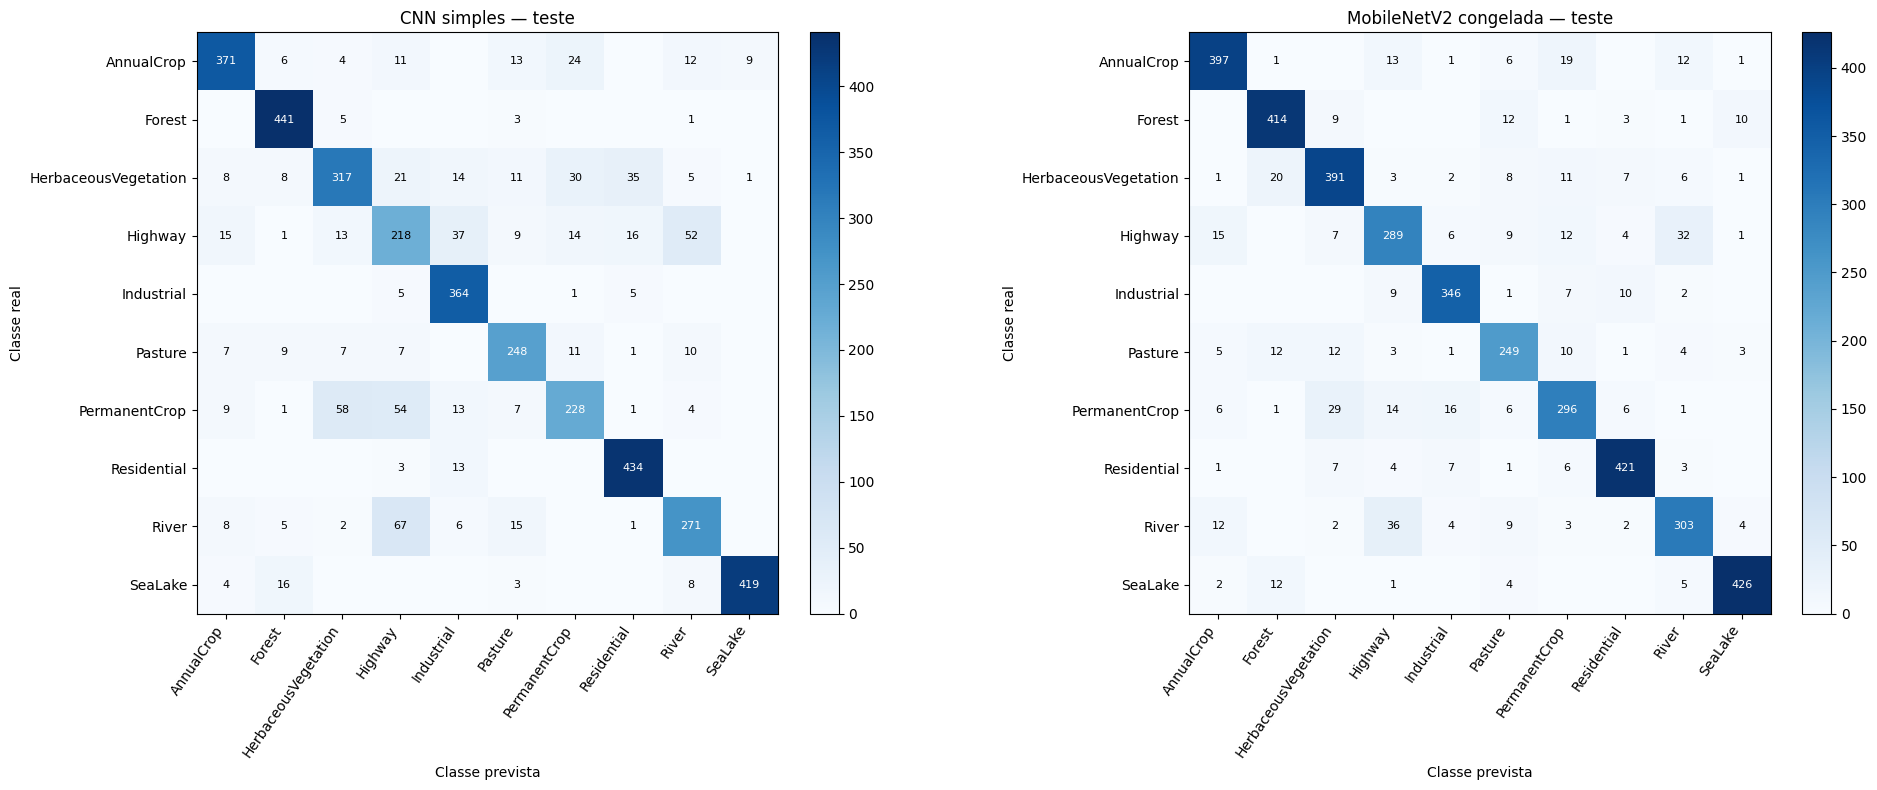

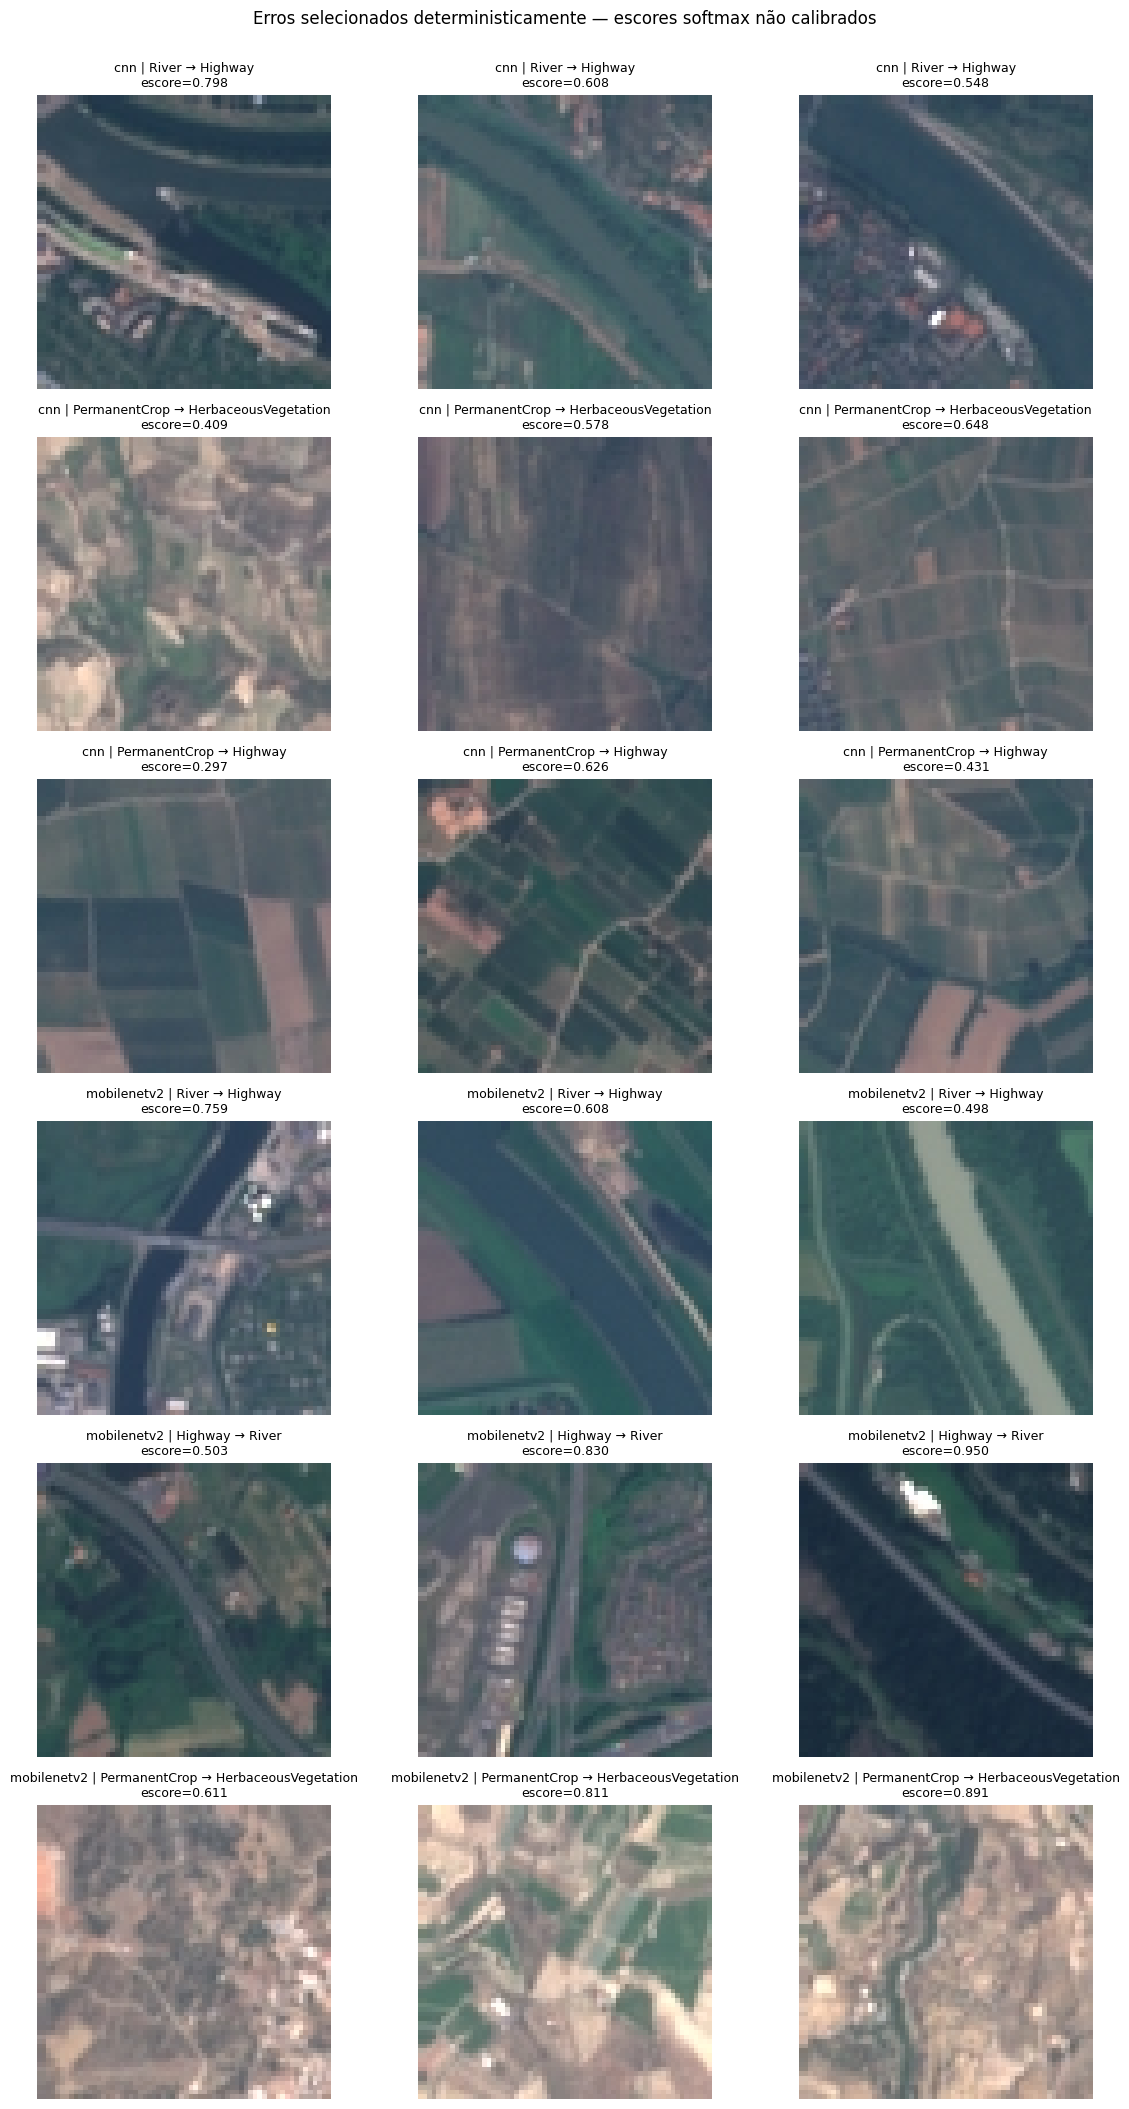

{
  "status": "deterministic_error_analysis_completed",
  "protocol_sha256": "ffa2be134d6efefab17ee279b667b01de3dc26fc3717ecabd830b2f8777a5df9",
  "sampling_rule": {
    "ordered_confusion_pairs_per_model": 3,
    "examples_per_pair": 3,
    "pair_order": "descending_count_then_true_index_then_predicted_index",
    "example_order": "sha256(master_seed|model|relative_path)"
  },
  "top_ordered_confusions": {
    "cnn": [
      {
        "true_class_index": 8,
        "true_class_name": "River",
        "predicted_class_index": 3,
        "predicted_class_name": "Highway",
        "count": 67
      },
      {
        "true_class_index": 6,
        "true_class_name": "PermanentCrop",
        "predicted_class_index": 2,
        "predicted_class_name": "HerbaceousVegetation",
        "count": 58
      },
      {
        "true_class_index": 6,
        "true_class_name": "PermanentCrop",
        "predicted_class_index": 3,
        "predicted_class_name": "Highway",
        "count": 54
      }

In [22]:
stage7_per_class_rows = []
for model_name in ('cnn', 'mobilenetv2'):
    report = stage7_metrics[model_name]['classification_report']
    for class_index, class_name in enumerate(CLASS_NAMES):
        stage7_per_class_rows.append({
            'model': model_name,
            'class_index': class_index,
            'class_name': class_name,
            'precision': float(report[class_name]['precision']),
            'recall': float(report[class_name]['recall']),
            'f1': float(report[class_name]['f1-score']),
            'support': int(report[class_name]['support']),
        })
stage7_write_csv_idempotent(
    STAGE7_PER_CLASS_PATH,
    ['model', 'class_index', 'class_name', 'precision', 'recall', 'f1', 'support'],
    stage7_per_class_rows,
)

stage7_comparison_rows = []
for model_name in ('cnn', 'mobilenetv2'):
    candidate = stage7_candidates[model_name]
    result = stage7_metrics[model_name]
    stage7_comparison_rows.append({
        'model': model_name,
        'attempt_id': candidate['attempt_id'],
        'test_accuracy': result['accuracy'],
        'test_f1_macro': result['f1_macro'],
        'test_mean_negative_log_likelihood': result['mean_negative_log_likelihood'],
        'training_seconds': float(candidate['training_seconds']),
        'epochs_completed': int(candidate['epochs_completed']),
        'total_parameters': int(candidate['parameters']['total']),
        'trainable_parameters': int(candidate['parameters']['trainable']),
        'test_inference_seconds': float(result['inference_seconds']),
    })
stage7_write_csv_idempotent(
    STAGE7_COMPARISON_PATH,
    list(stage7_comparison_rows[0].keys()),
    stage7_comparison_rows,
)

comparison_frame = pd.DataFrame(stage7_comparison_rows).set_index('model')
display(comparison_frame)
per_class_frame = pd.DataFrame(stage7_per_class_rows)
display(per_class_frame.pivot(
    index='class_name', columns='model', values=['precision', 'recall', 'f1', 'support']
))

confusion_figure, confusion_axes = plt.subplots(1, 2, figsize=(20, 8))
for axis, model_name, title in zip(
    confusion_axes,
    ('cnn', 'mobilenetv2'),
    ('CNN simples — teste', 'MobileNetV2 congelada — teste'),
):
    matrix = np.asarray(stage7_metrics[model_name]['confusion_matrix'])
    image = axis.imshow(matrix, cmap='Blues')
    axis.set_title(title)
    axis.set_xlabel('Classe prevista')
    axis.set_ylabel('Classe real')
    axis.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=55, ha='right')
    axis.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
    threshold = matrix.max() / 2.0
    for true_index in range(NUM_CLASSES):
        for predicted_index in range(NUM_CLASSES):
            value = int(matrix[true_index, predicted_index])
            if value:
                axis.text(
                    predicted_index, true_index, str(value),
                    ha='center', va='center', fontsize=8,
                    color='white' if value > threshold else 'black',
                )
    confusion_figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
confusion_figure.tight_layout()
stage7_confusion_path = STAGE7_FIGURES_DIR / 'confusion_matrices.png'
confusion_figure.savefig(stage7_confusion_path, dpi=160, bbox_inches='tight')
plt.show()
plt.close(confusion_figure)


def stage7_top_confusions(model_name, limit=3):
    matrix = np.asarray(stage7_metrics[model_name]['confusion_matrix'])
    pairs = [
        (int(matrix[true_index, predicted_index]), true_index, predicted_index)
        for true_index in range(NUM_CLASSES)
        for predicted_index in range(NUM_CLASSES)
        if true_index != predicted_index and matrix[true_index, predicted_index] > 0
    ]
    pairs.sort(key=lambda item: (-item[0], item[1], item[2]))
    return pairs[:limit]


stage7_error_example_rows = []
stage7_top_confusion_payload = {}
for model_name in ('cnn', 'mobilenetv2'):
    top_pairs = stage7_top_confusions(model_name, limit=3)
    stage7_top_confusion_payload[model_name] = [{
        'true_class_index': true_index,
        'true_class_name': CLASS_NAMES[true_index],
        'predicted_class_index': predicted_index,
        'predicted_class_name': CLASS_NAMES[predicted_index],
        'count': count,
    } for count, true_index, predicted_index in top_pairs]
    rows = stage7_predictions[model_name]['rows']
    for pair_rank, (count, true_index, predicted_index) in enumerate(top_pairs, 1):
        candidates = [
            row for row in rows
            if int(row['true_class_index']) == true_index
            and int(row['predicted_class_index']) == predicted_index
        ]
        candidates.sort(key=lambda row: hashlib.sha256(
            f'{MASTER_SEED}|{model_name}|{row["relative_path"]}'.encode('utf-8')
        ).hexdigest())
        for example_rank, row in enumerate(candidates[:3], 1):
            stage7_error_example_rows.append({
                'model': model_name,
                'confusion_pair_rank': pair_rank,
                'example_rank': example_rank,
                'relative_path': row['relative_path'],
                'true_class_index': true_index,
                'true_class_name': CLASS_NAMES[true_index],
                'predicted_class_index': predicted_index,
                'predicted_class_name': CLASS_NAMES[predicted_index],
                'pair_count': count,
                'max_softmax_score_uncalibrated': float(row['max_softmax_score']),
            })
stage7_error_example_fields = [
    'model', 'confusion_pair_rank', 'example_rank', 'relative_path',
    'true_class_index', 'true_class_name', 'predicted_class_index',
    'predicted_class_name', 'pair_count',
    'max_softmax_score_uncalibrated',
]
stage7_write_csv_idempotent(
    STAGE7_ERROR_EXAMPLES_PATH,
    stage7_error_example_fields,
    stage7_error_example_rows,
)

cnn_by_path = {
    row['relative_path']: row for row in stage7_predictions['cnn']['rows']
}
mobilenet_by_path = {
    row['relative_path']: row for row in stage7_predictions['mobilenetv2']['rows']
}
shared_error_count = 0
cnn_only_error_count = 0
mobilenet_only_error_count = 0
both_correct_count = 0
for relative_path in test_ids:
    cnn_row = cnn_by_path[relative_path]
    mobilenet_row = mobilenet_by_path[relative_path]
    if cnn_row['true_class_index'] != mobilenet_row['true_class_index']:
        raise RuntimeError('Rótulos divergentes entre os modelos.')
    cnn_wrong = cnn_row['predicted_class_index'] != cnn_row['true_class_index']
    mobilenet_wrong = (
        mobilenet_row['predicted_class_index'] != mobilenet_row['true_class_index']
    )
    if cnn_wrong and mobilenet_wrong:
        shared_error_count += 1
    elif cnn_wrong:
        cnn_only_error_count += 1
    elif mobilenet_wrong:
        mobilenet_only_error_count += 1
    else:
        both_correct_count += 1

stage7_error_analysis = {
    'status': 'deterministic_error_analysis_completed',
    'protocol_sha256': STAGE7_PROTOCOL_SHA256,
    'sampling_rule': STAGE7_PROTOCOL['error_sampling'],
    'top_ordered_confusions': stage7_top_confusion_payload,
    'prediction_overlap': {
        'both_correct': both_correct_count,
        'both_wrong': shared_error_count,
        'cnn_wrong_mobilenet_correct': cnn_only_error_count,
        'cnn_correct_mobilenet_wrong': mobilenet_only_error_count,
        'total': len(test_records),
    },
    'selected_examples': str(STAGE7_ERROR_EXAMPLES_PATH.relative_to(PROJECT_DIR)),
    'selected_example_count': len(stage7_error_example_rows),
    'visual_interpretation': 'hypotheses_only_not_proven_causes',
    'test_set_used': True,
}
write_json_atomically(STAGE7_ERROR_ANALYSIS_PATH, stage7_error_analysis)

records_by_relative_path = {record[2]: record for record in test_records}
error_columns = 3
error_rows = max(1, int(np.ceil(len(stage7_error_example_rows) / error_columns)))
error_figure, error_axes = plt.subplots(
    error_rows, error_columns, figsize=(12, 3.5 * error_rows), squeeze=False
)
for axis, selected in zip(error_axes.flat, stage7_error_example_rows):
    image_path = records_by_relative_path[selected['relative_path']][0]
    axis.imshow(plt.imread(image_path))
    axis.set_title(
        f"{selected['model']} | {selected['true_class_name']} → "
        f"{selected['predicted_class_name']}\n"
        f"escore={selected['max_softmax_score_uncalibrated']:.3f}",
        fontsize=9,
    )
    axis.axis('off')
for axis in error_axes.flat[len(stage7_error_example_rows):]:
    axis.axis('off')
if not stage7_error_example_rows:
    error_axes.flat[0].text(
        0.5, 0.5, 'Nenhum erro de classificação no teste.',
        ha='center', va='center', transform=error_axes.flat[0].transAxes,
    )
error_figure.suptitle(
    'Erros selecionados deterministicamente — escores softmax não calibrados',
    y=1.002,
)
error_figure.tight_layout()
stage7_error_figure_path = STAGE7_FIGURES_DIR / 'deterministic_error_examples.png'
error_figure.savefig(stage7_error_figure_path, dpi=160, bbox_inches='tight')
plt.show()
plt.close(error_figure)

print(json.dumps(stage7_error_analysis, indent=2, ensure_ascii=False))


### Demonstração de recarga e inferência

Uma imagem por classe é selecionada do teste por uma regra determinística. Os dois checkpoints são carregados novamente e as probabilidades obtidas são comparadas às predições persistidas da avaliação final. Diferenças além da tolerância interrompem a conclusão da etapa.


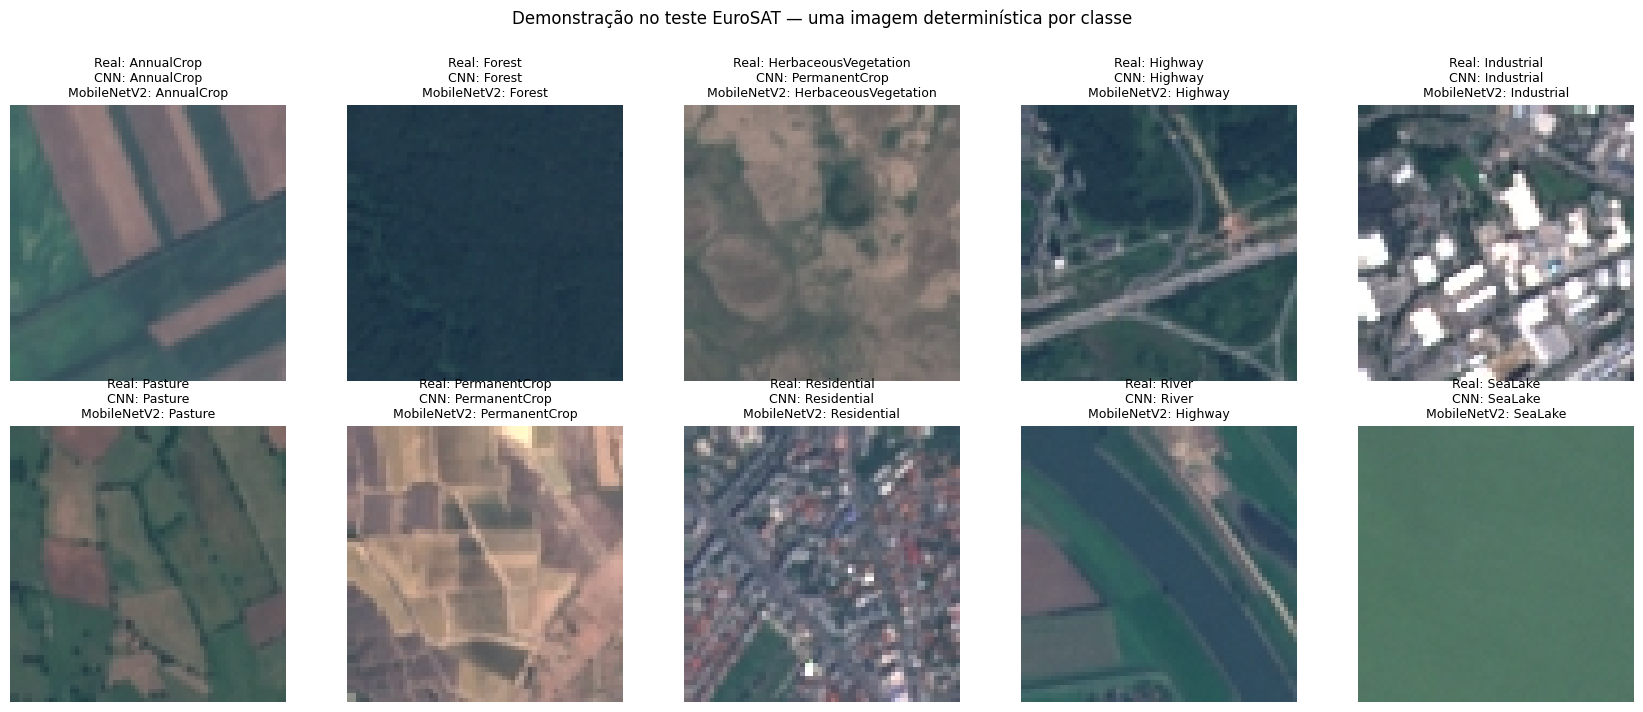

{
  "status": "stage7_completed",
  "test_examples": 4050,
  "test_metrics": {
    "cnn": {
      "accuracy": 0.8175308641975308,
      "f1_macro": 0.8081781485267093,
      "mean_negative_log_likelihood": 0.5069269597814811,
      "inference_seconds": 1.999723283999856
    },
    "mobilenetv2": {
      "accuracy": 0.8720987654320987,
      "f1_macro": 0.867186737320521,
      "mean_negative_log_likelihood": 0.3883765672496064,
      "inference_seconds": 12.021579928000165
    }
  },
  "mobilenetv2_minus_cnn": {
    "accuracy": 0.054567901234567895,
    "f1_macro": 0.059008588793811656,
    "training_seconds": 39.24787660499874
  },
  "descriptive_higher_test_f1_model": "mobilenetv2",
  "checkpoint_reload_verified": {
    "cnn": true,
    "mobilenetv2": true
  },
  "statistical_superiority_claimed": false,
  "test_set_used": true,
  "no_test_driven_adjustment": true,
  "summary": "artifacts/stage7_final_evaluation/final_summary.json"
}


In [23]:
stage7_demo_records = []
for class_index in range(NUM_CLASSES):
    candidates = [record for record in test_records if record[1] == class_index]
    if not candidates:
        raise RuntimeError(f'Classe ausente no teste: {CLASS_NAMES[class_index]}')
    candidates.sort(key=lambda record: hashlib.sha256(
        f'{MASTER_SEED}|demo|{record[2]}'.encode('utf-8')
    ).hexdigest())
    stage7_demo_records.append(candidates[0])

stage7_demo_dataset = make_dataset(
    stage7_demo_records, batch_size=NUM_CLASSES, training=False
)
stage7_demo_images, stage7_demo_labels = next(iter(stage7_demo_dataset))
if not np.array_equal(
    stage7_demo_labels.numpy(), np.arange(NUM_CLASSES, dtype=np.int32)
):
    raise RuntimeError('A demonstração não preservou a ordem das classes.')

stage7_demo_probabilities = {}
stage7_demo_verification = {}
for model_name in ('cnn', 'mobilenetv2'):
    tf.keras.backend.clear_session()
    gc.collect()
    checkpoint_path = (
        stage7_candidate_roots[model_name]
        / stage7_candidates[model_name]['selected_checkpoint']
    )
    model = load_model_for_inference(
        model_name, MODEL_SPECS[model_name], checkpoint_path
    )
    probabilities = model(stage7_demo_images, training=False).numpy()
    persisted_probabilities = np.asarray([
        stage7_predictions[model_name]['probabilities'][test_ids.index(record[2])]
        for record in stage7_demo_records
    ])
    np.testing.assert_allclose(
        probabilities, persisted_probabilities, rtol=1e-5, atol=1e-6
    )
    max_difference = float(np.max(np.abs(
        probabilities - persisted_probabilities
    )))
    stage7_demo_probabilities[model_name] = probabilities
    stage7_demo_verification[model_name] = {
        'artifact_root': stage7_candidate_root_aliases[model_name],
        'checkpoint': stage7_candidates[model_name]['selected_checkpoint'],
        'checkpoint_sha256': stage7_candidates[model_name][
            'selected_checkpoint_sha256'
        ],
        'reloaded': True,
        'max_prediction_difference_vs_persisted_test_predictions': max_difference,
        'verified': True,
    }
    del model

demo_figure, demo_axes = plt.subplots(2, 5, figsize=(17, 7))
for index, (axis, record) in enumerate(zip(demo_axes.flat, stage7_demo_records)):
    cnn_prediction = int(np.argmax(stage7_demo_probabilities['cnn'][index]))
    mobilenet_prediction = int(np.argmax(
        stage7_demo_probabilities['mobilenetv2'][index]
    ))
    axis.imshow(np.clip(stage7_demo_images[index].numpy() / 255.0, 0.0, 1.0))
    axis.set_title(
        f"Real: {CLASS_NAMES[record[1]]}\n"
        f"CNN: {CLASS_NAMES[cnn_prediction]}\n"
        f"MobileNetV2: {CLASS_NAMES[mobilenet_prediction]}",
        fontsize=9,
    )
    axis.axis('off')
demo_figure.suptitle(
    'Demonstração no teste EuroSAT — uma imagem determinística por classe',
    y=1.01,
)
demo_figure.tight_layout()
stage7_demo_figure_path = STAGE7_FIGURES_DIR / 'inference_demonstration.png'
demo_figure.savefig(stage7_demo_figure_path, dpi=160, bbox_inches='tight')
plt.show()
plt.close(demo_figure)

stage7_demo_payload = {
    'status': 'checkpoint_reload_and_inference_verified',
    'protocol_sha256': STAGE7_PROTOCOL_SHA256,
    'origin': 'reserved_eurosat_test_split',
    'external_independent_evaluation': False,
    'selection_rule': STAGE7_PROTOCOL['inference_demonstration']['selection'],
    'examples': [{
        'relative_path': record[2],
        'true_class_index': int(record[1]),
        'true_class_name': CLASS_NAMES[int(record[1])],
    } for record in stage7_demo_records],
    'models': stage7_demo_verification,
    'figure': str(stage7_demo_figure_path.relative_to(PROJECT_DIR)),
    'test_set_used': True,
}
write_json_atomically(STAGE7_DEMO_PATH, stage7_demo_payload)

stage7_f1_delta = (
    stage7_metrics['mobilenetv2']['f1_macro']
    - stage7_metrics['cnn']['f1_macro']
)
stage7_accuracy_delta = (
    stage7_metrics['mobilenetv2']['accuracy']
    - stage7_metrics['cnn']['accuracy']
)
stage7_descriptive_higher_f1_model = max(
    ('cnn', 'mobilenetv2'),
    key=lambda name: stage7_metrics[name]['f1_macro'],
)
stage7_final_summary = {
    'status': 'stage7_completed',
    'protocol_sha256': STAGE7_PROTOCOL_SHA256,
    'test_examples': len(test_records),
    'class_order': CLASS_NAMES,
    'candidates': stage7_candidate_registry,
    'test_metrics': {
        model_name: {
            'accuracy': stage7_metrics[model_name]['accuracy'],
            'f1_macro': stage7_metrics[model_name]['f1_macro'],
            'mean_negative_log_likelihood': (
                stage7_metrics[model_name]['mean_negative_log_likelihood']
            ),
            'inference_seconds': stage7_metrics[model_name]['inference_seconds'],
        }
        for model_name in ('cnn', 'mobilenetv2')
    },
    'mobilenetv2_minus_cnn': {
        'accuracy': stage7_accuracy_delta,
        'f1_macro': stage7_f1_delta,
        'training_seconds': (
            float(stage7_candidates['mobilenetv2']['training_seconds'])
            - float(stage7_candidates['cnn']['training_seconds'])
        ),
    },
    'descriptive_higher_test_f1_model': stage7_descriptive_higher_f1_model,
    'statistical_superiority_claimed': False,
    'formal_attempts_per_model': {'cnn': 2, 'mobilenetv2': 1},
    'cost_scope': (
        'Training time of the selected candidate for each model; technical '
        'probes and human time are excluded. Both selected runs used Tesla T4, '
        'but their TensorFlow versions differ.'
    ),
    'error_analysis': stage7_error_analysis,
    'inference_demonstration': stage7_demo_payload,
    'artifacts': {
        'protocol': str(STAGE7_PROTOCOL_PATH.relative_to(PROJECT_DIR)),
        'metrics': str(STAGE7_METRICS_PATH.relative_to(PROJECT_DIR)),
        'per_class_metrics': str(STAGE7_PER_CLASS_PATH.relative_to(PROJECT_DIR)),
        'comparison': str(STAGE7_COMPARISON_PATH.relative_to(PROJECT_DIR)),
        'confusion_matrices': str(stage7_confusion_path.relative_to(PROJECT_DIR)),
        'error_examples': str(STAGE7_ERROR_EXAMPLES_PATH.relative_to(PROJECT_DIR)),
        'error_figure': str(stage7_error_figure_path.relative_to(PROJECT_DIR)),
        'demonstration': str(STAGE7_DEMO_PATH.relative_to(PROJECT_DIR)),
    },
    'limitations': [
        'Two CNN attempts and one MobileNetV2 attempt do not establish statistical superiority.',
        'Selected training times used different TensorFlow versions and are descriptive only.',
        'The random split does not demonstrate generalization to unseen regions.',
        'The architectures, initialization, and training regimes differ; the design does not isolate only ImageNet pretraining.',
        'Softmax scores were not calibrated.',
        'Test images are not an external independent dataset.',
    ],
    'test_set_used': True,
    'no_test_driven_adjustment': True,
}
if STAGE7_FINAL_SUMMARY_PATH.exists():
    with STAGE7_FINAL_SUMMARY_PATH.open(encoding='utf-8') as file:
        persisted_stage7_summary = json.load(file)
    if persisted_stage7_summary != stage7_final_summary:
        raise RuntimeError('O resumo final persistido diverge da recomputação.')
else:
    write_json_atomically(STAGE7_FINAL_SUMMARY_PATH, stage7_final_summary)

stage7_state = {
    'status': 'stage7_completed',
    'protocol_sha256': STAGE7_PROTOCOL_SHA256,
    'test_set_accessed': True,
    'test_examples': len(test_records),
    'final_summary': str(STAGE7_FINAL_SUMMARY_PATH.relative_to(PROJECT_DIR)),
    'final_summary_sha256': hashlib.sha256(
        STAGE7_FINAL_SUMMARY_PATH.read_bytes()
    ).hexdigest(),
    'no_test_driven_adjustment': True,
}
write_json_atomically(STAGE7_STATE_PATH, stage7_state)

print(json.dumps({
    'status': stage7_final_summary['status'],
    'test_examples': stage7_final_summary['test_examples'],
    'test_metrics': stage7_final_summary['test_metrics'],
    'mobilenetv2_minus_cnn': stage7_final_summary['mobilenetv2_minus_cnn'],
    'descriptive_higher_test_f1_model': (
        stage7_final_summary['descriptive_higher_test_f1_model']
    ),
    'checkpoint_reload_verified': {
        model_name: stage7_demo_verification[model_name]['verified']
        for model_name in ('cnn', 'mobilenetv2')
    },
    'statistical_superiority_claimed': False,
    'test_set_used': True,
    'no_test_driven_adjustment': True,
    'summary': str(STAGE7_FINAL_SUMMARY_PATH.relative_to(PROJECT_DIR)),
}, indent=2, ensure_ascii=False))

### Registro da avaliação final

As quatro células desta seção foram executadas em ordem. O protocolo foi persistido antes do primeiro acesso ao teste, e as predições, métricas, tabelas, matrizes e exemplos de erro foram produzidos a partir dos dois candidatos congelados. A avaliação abrangeu 4.050 imagens: a CNN obteve acurácia de 0,8175 e F1 macro de 0,8082; a MobileNetV2 obteve acurácia de 0,8721 e F1 macro de 0,8672.

Os dois checkpoints foram recarregados e reproduziram as predições persistidas. Não foi feita alegação de superioridade estatística nem houve ajuste orientado pelo teste (`no_test_driven_adjustment: true`). Após essa avaliação, o conjunto de teste passou a ser considerado exposto e não foi reutilizado para orientar configurações.


## 14. Conclusões e limitações

### Síntese dos resultados no teste

| Modelo | Acurácia | F1 macro | NLL média | Tempo de inferência registrado |
|---|---:|---:|---:|---:|
| CNN simples | 0,8175 | 0,8082 | 0,5069 | 2,00 s |
| MobileNetV2 congelada | **0,8721** | **0,8672** | **0,3884** | 12,02 s |

No protocolo realizado, a MobileNetV2 apresentou a maior qualidade descritiva no conjunto de teste: **+0,0546 de acurácia** e **+0,0590 de F1 macro** em relação à CNN. Sua NLL média também foi menor. O comportamento foi consistente com a validação, sem inversão do modelo de maior F1 macro.

A MobileNetV2 obteve maior F1 em oito das dez classes. A CNN teve F1 superior em `Forest` e uma vantagem pequena em `SeaLake`. As maiores confusões da MobileNetV2 envolveram `River → Highway` (36 imagens), `Highway → River` (32) e `PermanentCrop → HerbaceousVegetation` (29). Entre as 4.050 imagens, os dois modelos acertaram 3.007 e erraram 214; a MobileNetV2 corrigiu 525 casos errados pela CNN, enquanto a CNN corrigiu 304 casos errados pela MobileNetV2.

Os treinamentos selecionados registraram 327,81 s para a CNN e 367,06 s para a MobileNetV2. A diferença de 39,25 s é apenas descritiva: ambos usaram Tesla T4, mas foram executados com versões diferentes do TensorFlow. Da mesma forma, os tempos de inferência correspondem a uma única medição do fluxo e não constituem benchmark de latência.

### Resposta à pergunta experimental

Dentro desta divisão, destas configurações e destas tentativas, a MobileNetV2 congelada ofereceu o melhor resultado de classificação. A CNN permaneceu menor e apresentou menor tempo de inferência na medição registrada, mas esse aspecto não foi avaliado em um benchmark controlado. Os resultados sustentam uma preferência prática pela MobileNetV2 quando a prioridade é a qualidade preditiva neste protocolo, sem demonstrar superioridade estatística ou causalidade exclusiva do pré-treinamento no ImageNet.

### Limitações

- foram realizadas duas tentativas formais da CNN e uma da MobileNetV2, todas sob uma única semente;
- a divisão aleatória por imagem não demonstra generalização para regiões geográficas não vistas;
- arquitetura, inicialização e regime de treinamento diferem entre as abordagens;
- a entrada de 64 × 64 preserva a resolução nativa, mas difere da resolução padrão associada aos pesos ImageNet;
- os escores softmax não foram calibrados;
- o teste pertence ao EuroSAT e não é uma avaliação externa independente;
- o estudo utiliza somente RGB e não explora as bandas multiespectrais do Sentinel-2;
- nenhuma alteração de modelo foi realizada após a exposição ao teste.


## 15. Reprodutibilidade e organização da entrega

### Nível verificado

O notebook foi executado em ordem, do ambiente à avaliação final, em uma sessão reiniciada do Google Colab. A aquisição e a integridade do dataset, a reconstrução da divisão, a recarga dos dois candidatos, a recomputação das métricas e figuras e a equivalência das predições de demonstração foram verificadas. Na consolidação final, os treinamentos não foram repetidos: foram reutilizados os artefatos formais já selecionados e validados.

Portanto, foi demonstrada **reprodução por recarga de artefatos e recomputação da avaliação**. Uma reprodução integral com novos treinamentos não foi executada durante a finalização e pode apresentar pequenas variações mesmo com a semente fixa.

### Organização dos materiais de reprodução

O pacote de entrega contém o notebook executado, o módulo de auditoria, configurações, resultados finais, figuras, dependências, `README.md` e `.gitignore`. O dataset bruto e os checkpoints não são versionados; as instruções para obtenção dos dados, configuração de `EUROSAT_PROJECT_DIR` e reprodução do experimento estão documentadas no `README.md`.

Os caminhos utilizados são genéricos e relativos à raiz configurável do projeto.


## 16. Referências

Fontes primárias consultadas na definição do protocolo e verificadas novamente em 12/10/2026:

1. Helber, P.; Bischke, B.; Dengel, A.; Borth, D. *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*. IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing, 12(7), 2217–2226. https://doi.org/10.1109/JSTARS.2019.2918242
2. Helber, P.; Bischke, B.; Dengel, A.; Borth, D. *EuroSAT — distribuição RGB, versão v2*. Zenodo. https://doi.org/10.5281/zenodo.7711810
3. Helber et al. *EuroSAT: Land Use and Land Cover Classification with Sentinel-2*. Repositório dos autores. https://github.com/phelber/EuroSAT
4. TensorFlow. *Transfer learning and fine-tuning*. https://www.tensorflow.org/tutorials/images/transfer_learning
5. TensorFlow. *tf.keras.applications.MobileNetV2*. https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2
6. scikit-learn 1.6. *F1 score*. https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.f1_score.html
7. scikit-learn 1.6. *Common pitfalls and recommended practices*. https://scikit-learn.org/1.6/common_pitfalls.html

As versões efetivamente utilizadas estão registradas nas saídas do ambiente e nos arquivos de configuração de cada tentativa.
